In [1]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
from Bio import pairwise2
from pprint import pprint
import itertools
import csv
import plotly.graph_objects as go
import plotly.subplots as subplots
import seaborn as sns
import matplotlib as mpl
from matplotlib import colors as mcolors
import numpy as np
from collections import Counter
from statistics import mean
import math
import mpltern
import ternary
from plotly.subplots import make_subplots
import os
from statannotations.Annotator import Annotator
import scipy
from scipy.stats import shapiro 
from scipy.stats import lognorm
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import ColorConverter
from matplotlib.colors import ListedColormap
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.gofplots import ProbPlot
import ast
import matplotlib.ticker as mticker
from cycler import cycler

/Users/sarah/git/NguyenLab/.venv/lib/python3.13/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


# ToDo
- update scRNA_bc_path
- update multi_int_file path

In [2]:
# Function for writing a dictionary of dictionaries to an excel file
## Each tumor as a key in the original, with data as values in a secondary dictionary
## Sets Sequence as the index
def excel_save(dictionary, filepath, multiind=False):
    writer = pd.ExcelWriter(filepath)

    for key, val in dictionary.items():
        if multiind:
            columns = pd.MultiIndex.from_tuples(list(val[0].keys())[1:])
            df = pd.DataFrame(val, columns=columns, index=[x["Sequence"] for x in val])
            df.index.rename("Sequence", inplace=True)
        else:
            df = pd.DataFrame(val)
            df.set_index("Sequence", inplace=True)
        df.to_excel(writer, sheet_name=key)

    writer.close()


In [3]:
# Get the data 
path = "../data_files/amplicon_data/GE681B_clones_filtered.xlsx"
pathA = "../data_files/amplicon_data/GE681A_clones.xlsx"
path_num = "../data_files/amplicon_data/Tumour cell counts.xlsx"
scRNA_bc_path = "../data_files/scRNAseq_bc_response/sample_final_bc_response"

# Get a list of scRNAseq barcode association files
scRNA_bc_files = [f for f in os.listdir(scRNA_bc_path)]

# Read the data into pandas
xls = pd.ExcelFile(path)
xlsA = pd.ExcelFile(pathA)
cell_counts = pd.ExcelFile(path_num)

In [4]:
# Parse Excel file into one big dataframe with all data

# Parse all sheets in excel files into DataFrames and put them into a list
## Set up data structures
dfs = []
names = xls.sheet_names
namesA = xlsA.sheet_names
cohorts = {"U": "Untreated", "C": "Carboplatin", "P": "Paclitaxel"}

## Collect and clean data from primary samples
for i in range(0, 4):
    sheet = xlsA.parse(i, skiprows=[0])[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP', 'var_seq', 'n_reads', 'FRV', 'logFRV', 'cell', 'adjusted','Time (days)', 'Generations', 'Doubling time']]
    sheet[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP']] = sheet[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP']].ffill()
    sheet["var_seq"] = sheet["var_seq"].apply(lambda x: str(x).strip()).apply(lambda x: x.upper())
    sheet["Tumor"] = namesA[i].strip().split("-")[0]
    sheet["Cohort"] = "Primary"
    sheet["BC"] = 1
    sheet["Mouse"] = sheet.apply(lambda x: x["sample"].split("_")[0], axis = 1)
    mice = sheet["Mouse"].unique()
    mouse_dict = {mouse: idx+1 for idx, mouse in enumerate(mice)}
    sheet["Mouse num"] = sheet["Mouse"].map(mouse_dict)
    sheet["%GFP+"] = sheet.apply(lambda x: x["%GFP+"] * 100 if x["%GFP+"] < 1 else x["%GFP+"], axis = 1)
    sheet["%sequenced"] = sheet.apply(lambda x: x["%sequenced"] * 100 if x["%sequenced"] < 1 else x["%sequenced"], axis = 1)
    dfs.append(sheet)

## Collect and clean data from secondary samples
for i in range(0, len(names)):
    sheet = xls.parse(i, skiprows=[0])[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP', 'var_seq', 'n_reads', 'FRV', 'logFRV', 'cell', 'adjusted', "BC", 'Time (days)', 'Generations', 'Doubling time']]
    sheet[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP']] = sheet[['sample', 'cells injected', '%GFP+', '%sequenced', 'SLX', 'UDP']].ffill()
    sheet["var_seq"] = sheet["var_seq"].apply(lambda x: str(x).strip()).apply(lambda x: x.upper())
    sheet["Tumor"] = names[i].strip().split("-")[0]
    sheet["Cohort"] = cohorts[names[i].strip().split(" ")[-1]]
    sheet["%GFP+"] = sheet.apply(lambda x: x["%GFP+"] * 100 if x["%GFP+"] < 1 else x["%GFP+"], axis = 1)
    sheet["%sequenced"] = sheet.apply(lambda x: x["%sequenced"] * 100 if x["%sequenced"] < 1 else x["%sequenced"], axis = 1)
    sheet["Mouse"] = sheet.apply(lambda x: x["sample"].split("_")[0] if x["sample"][0] == "M" else (x["sample"].split("_")[1] if x["sample"][0:4] == "REDO" else x["sample"].split("_")[2]), axis = 1)
    mice = sheet["Mouse"].unique()
    mouse_dict = {mouse: idx+1 for idx, mouse in enumerate(mice)}
    sheet["Mouse num"] = sheet["Mouse"].map(mouse_dict)
    dfs.append(sheet)

# Join all DataFrames together into one dataset, remove spaces from column names, and remove rows with no adjusted cell count
data = pd.concat(dfs, join="outer", ignore_index=True)
data = data.rename(columns=lambda x: x.strip())
data.dropna(subset=["adjusted"], inplace=True)

# Filter out data from BC2
BC1_data = data.loc[data["BC"] == 1]

# Import and format tumor cell counts into a 'counts' dataframe
counts = cell_counts.parse()
m21173_total = int(counts.loc[counts["Xenografts"] == "STG139-X5_BC1&2LN_M00021173_T2"]["Cell yield"]) + int(counts.loc[counts["Xenografts"] == "STG139-X5_BC1&2LN_M00021173_T1"]["Cell yield"])
counts.loc[len(counts.index)] = ["STG139-X5_BC1&2LN_M00021173", "No", m21173_total]
counts["Mouse"] = counts["Xenografts"].str.replace("-", "_").str.split("_").str[-1]
counts = counts.loc[(counts["Mouse"] != "T1") & (counts["Mouse"] != "T2")].reset_index(drop=True)
counts = counts[['Cell yield', 'Mouse']]

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/2747015017.py:51: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  m21173_total = int(counts.loc[counts["Xenografts"] == "STG139-X5_BC1&2LN_M00021173_T2"]["Cell yield"]) + int(counts.loc[counts["Xenografts"] == "STG139-X5_BC1&2LN_M00021173_T1"]["Cell yield"])


In [5]:
# Filter for relevant mice
# List of propagated mice
prop_mice = ["AN21-021161", "AN21-021169", "AN21-021165", "AN21-021162"]
# dataframe with only primary, propagated mice
prop_mice_df = BC1_data.loc[BC1_data["Mouse"].isin(prop_mice)]
# dataframe with only secondary mice
secondary_df = BC1_data.loc[BC1_data["Cohort"] != "Primary"]
# Concatenate the propagated mice and secondary mice dataframe
full_data_unmerged = pd.concat([prop_mice_df, secondary_df], join="outer", ignore_index=True).drop(columns=["sample"])

# Merge any rows with the same barcode within the same sample and recalculate generations, adjusted, and doubling time
grouping_cols = ["Tumor", "Cohort", "Mouse", "var_seq"]
agg_dict = {}
for col in full_data_unmerged.columns:
    if col not in grouping_cols and col not in  ["Doubling time", "adjusted", "Generations"]:
        agg_dict[col] = "first"
agg_dict["cell"] = "sum"
agg_dict["%sequenced"] = "sum"
merged = full_data_unmerged.groupby(grouping_cols).agg(agg_dict).reset_index()
merged["%sequenced"] = merged.groupby(["Tumor", "Cohort", "Mouse"])["%sequenced"].transform("max")
merged["adjusted"] = merged["cell"] * (100 / merged["%sequenced"])
merged["Generations"] = np.log10(merged["adjusted"]) / np.log10(2)
merged["Doubling time"] = merged["Time (days)"] / merged["Generations"]
full_data_unmerged = merged

In [6]:
# Set up a dataframe that looks at individual BC1 barcode sequences 
    # and says at a glance which mice they were found in, how many were found, and doubling time
    # Primary barcodes only, ALL MODELS TOGETHER

# Set up dataframe with each unique barcode and the model it was found in, in only propagated primary and secondary cohorts
unique_seqs = full_data_unmerged.drop_duplicates(subset=["var_seq"])["var_seq"]
secondary_cohorts = ["Untreated", "Carboplatin", "Paclitaxel"]

# Set up a list to hold all the data
num_clones_BC1_v2 = []

# Iterate through each unique sequence found in the model
for seq in unique_seqs:
    seq_data = {("", "Sequence"): seq}
    # Iterate through each tumour 
    for model in full_data_unmerged["Tumor"].unique():
        # Set up a dictionary to hold data for each sequence, and instantiate with values
        # each seq will be a row in the final dataframe
        seq_data[(model, "Primary")] = 0
        for cohort in secondary_cohorts:
            for i in range(1, 4):
                seq_data[(model, f"{cohort} {i}")] = 0
    # Iterate through each row in the original dataframe from the model from the mouse
    # (the relevant columns this has are var_seq, adjusted (cell count), Cohort, Mouse num, Tumour)
    for index, row in full_data_unmerged.iterrows():
        # Compare current sequence to sequence in the row
        score = pairwise2.align.globalms(seq, row["var_seq"], 1, 0, -1, -1, score_only=True)
        # If matches, collect data from the row
        # NOTE: if any sequences are recorded more than once in the same mouse (ie for repeat runs etc)
            # the last set of values will replace any previous values
        if score == 31:
            if row["Cohort"] != "Primary":
                seq_data[(f"{row['Tumor']}", f"{row['Cohort']} {row['Mouse num']}")] = round(row["adjusted"], 2)
            else:
                seq_data[(f"{row['Tumor']}", f"{row['Cohort']}")] = round(row["adjusted"], 2)
    num_clones_BC1_v2.append(seq_data)


In [7]:
# Convert list of dictionaries with seq and number of clones for each seq in ALL models to dataframe
seq_cols = pd.MultiIndex.from_tuples([x for x in num_clones_BC1_v2[0].keys()])
seq_info = pd.DataFrame(num_clones_BC1_v2, columns=seq_cols)
seq_info = seq_info.set_index(("", "Sequence"), drop=True)
seq_info.index.name = "Sequence"

In [29]:
# Characterize each clone as diminished, minimal change, expanded and add to the full dataframe - including propagating primary clones
## Untreated do not get a designation - only treated; so for response for untreated, denote as "Untreated"
# Also creates a second dataframe with average changes in clone sizes between primary and secondary cohorts and secondary untreated and treated cohorts (where clones are present in at least 1 tumor)

# Create columns in full dataset for Response to treatment and Consistency and prep data structures
full_data_unmerged["Treated Response"] = ""
full_data_unmerged["Treated Response Consistency"] = ""
full_data_unmerged["Untreated Carboplatin Response"] = ""
full_data_unmerged["Untreated Paclitaxel Response"] = ""
full_stats = {}

response_classes_for_bargraph_treated_response = {}
clonal_comp_for_bargraph_treated_response = {}
clonal_comp_for_bargraph_treated_response_primary = {}

# Create dictionary for response consistency heatmap
valid_barcodes_per_model = {}

for model in full_data_unmerged["Tumor"].unique():
    tumor_seq_info = seq_info[model]
    tumor_seq_info = tumor_seq_info.loc[(tumor_seq_info!=0).any(axis=1)]
    valid_barcodes_per_model[model] = tumor_seq_info.index.tolist()
    model_info = []
    response_consistency_list = []

    for index, row in tumor_seq_info.iterrows():
        # Set up dict to hold info about bc row
        row_meta = {"barcode info": {
                        "barcode": index,
                        "primary_cells": 0, 
                        "prop_trans_emerg": "Temp",
                        "secondary_presence": 0,
                        "primary_proportion": 0, 
                        "all_consistencies": [],
                        "Change in cell number: Untreated to Paclitaxel": [], 
                        "Change in cell number: Untreated to Carboplatin": [], 
                        "Change in cell number: Primary to Paclitaxel": [], 
                        "Change in cell number: Primary to Carboplatin": [], 
                        "Change in cell number: Primary to Untreated": [], 
                        "Paclitaxel - Untreated proportion": [], 
                        "Carboplatin - Untreated proportion": [], 
                        "Paclitaxel - Primary proportion": [], 
                        "Carboplatin - Primary proportion": [], 
                        "Untreated - Primary proportion": [], 
                        "Percent change: Untreated to Carboplatin": [],
                        "Percent change: Untreated to Paclitaxel": [],
                        "Percent change: Primary to Untreated": [],
                        "Percent change: Primary to Carboplatin": [],
                        "Percent change: Primary to Paclitaxel": []
                    },
                    "secondary cohort info": {
                        "Untreated": {
                            "all_num_cells": [],
                            "all_proportions": [], 
                            "mouse": [], 
                            "nonzero_num_cells": [],
                            "nonzero_proportion": [], 
                            "agg_response": "Untreated", 
                            "presence": 0, 
                            "avg_nonzero": 0,
                            "all_treated_responses": [],
                            "all_untreated_Carboplatin_responses": [],
                            "all_untreated_Paclitaxel_responses": [],
                            "avg_nonzero_proportion": 0, 
                            "percent change": {
                                "Carboplatin": [],
                                "Paclitaxel": []
                            }
                        }, 
                        "Carboplatin": {
                            "all_num_cells": [],
                            "all_proportions": [], 
                            "mouse": [], 
                            "nonzero_num_cells": [],
                            "nonzero_proportion": [], 
                            "agg_response": "Temp", 
                            "presence": 0, 
                            "response_consistency": "Temp",
                            "avg_nonzero": 0,
                            "all_treated_responses": [],
                            "all_untreated_Carboplatin_responses": [],
                            "all_untreated_Paclitaxel_responses": [],
                            "avg_nonzero_proportion": 0, 
                            "percent change": {
                                "Untreated": []
                            }
                        }, 
                        "Paclitaxel": {
                            "all_num_cells": [],
                            "all_proportions": [], 
                            "mouse": [], 
                            "nonzero_num_cells": [], 
                            "nonzero_proportion": [], 
                            "agg_response": "Temp", 
                            "presence": 0, 
                            "response_consistency": "Temp",
                            "avg_nonzero": 0,
                            "all_treated_responses": [],
                            "all_untreated_Carboplatin_responses": [],
                            "all_untreated_Paclitaxel_responses": [],
                            "avg_nonzero_proportion": 0, 
                            "percent change": {
                                "Untreated": []
                            }
                    }}}
        row_cohort = row_meta["secondary cohort info"]
        row_bc = row_meta["barcode info"]

        # Collect number of cells in each treated cohort for given barcode and replicates it's present in for each cohort
        for column, value in row.items():
            cohort = str(column).split(" ")[0]
            if cohort == "Primary":
                row_bc["primary_cells"] = value
            else:
                mouse_num = str(column).split(" ")[1]
                row_cohort[cohort]["all_num_cells"].append(value)
                row_cohort[cohort]["mouse"].append(mouse_num)
                if value > 0:
                    row_bc["secondary_presence"] += 1
                    row_cohort[cohort]["nonzero_num_cells"].append(value)
                    row_cohort[cohort]["presence"] += 1

        # Identify as propagating, transient, or emerging
        if row_bc["primary_cells"] > 0 and row_bc["secondary_presence"] >= 1:
            row_bc["prop_trans_emerg"] = "Propagating"
        elif row_bc["primary_cells"] > 0 and row_bc["secondary_presence"] == 0:
            row_bc["prop_trans_emerg"] = "Transient"
        else:
            row_bc["prop_trans_emerg"] = "Emerging"
                
        # Calculate average nonzero cell numbers
        for cohort in row_cohort.keys():
            if row_cohort[cohort]["presence"] > 0:
                row_cohort[cohort]["avg_nonzero"] = mean(row_cohort[cohort]["nonzero_num_cells"])      

        # Calculate overall binary responses from nonzero averages
        for cohort in row_cohort.keys():
            if cohort != "Untreated": 
                if row_cohort["Untreated"]["presence"] > 0:
                    change = ((row_cohort[cohort]["avg_nonzero"] - row_cohort["Untreated"]["avg_nonzero"])/row_cohort["Untreated"]["avg_nonzero"])*100
                    if change <= -30:
                        row_cohort[cohort]["agg_response"] = "Diminished"
                    elif -30 < change < 20:
                        row_cohort[cohort]["agg_response"] = "Minimal change"
                    else:
                        row_cohort[cohort]["agg_response"] = "Expanded"
                elif row_cohort["Untreated"]["presence"] == 0 and row_cohort[cohort]["presence"] > 0:
                    row_cohort[cohort]["agg_response"] = "Expanded"
                elif row_cohort["Untreated"]["presence"] == 0 and row_cohort[cohort]["presence"] == 0:
                    row_cohort[cohort]["agg_response"] = "Not present"                        

        # Classify clones per replicate with a response to treatment and calculate deltas
        for cohort in row_cohort.keys():
            for i in range(0,3):
                curr_num_cells = row_cohort[cohort]["all_num_cells"][i]

                # Calculate primary to secondary percent change
                if row_bc["primary_cells"] > 0:
                    row_bc[f"Percent change: Primary to {cohort}"].append(((curr_num_cells - row_bc["primary_cells"])/row_bc["primary_cells"])*100)
                elif row_bc["primary_cells"] == 0 and curr_num_cells > 0:
                    row_bc[f"Percent change: Primary to {cohort}"].append(100)
                elif row_bc["primary_cells"] == 0 and curr_num_cells == 0:
                    row_bc[f"Percent change: Primary to {cohort}"].append(0)

                # Deal with untreated
                if cohort == "Untreated": 
                    # Calculate deltas for untreated vs primary
                    row_bc["Change in cell number: Primary to Untreated"].append((curr_num_cells - row_bc["primary_cells"]))

                    # Classify as not present or generic "Untreated" 
                    if curr_num_cells > 0:
                        curr_response = "Untreated"

                        pac_change = ((row_cohort["Paclitaxel"]["avg_nonzero"] - curr_num_cells)/curr_num_cells)*100
                        carb_change = ((row_cohort["Carboplatin"]["avg_nonzero"] - curr_num_cells)/curr_num_cells)*100

                        row_cohort[cohort]["percent change"]["Carboplatin"].append(carb_change)
                        row_cohort[cohort]["percent change"]["Paclitaxel"].append(pac_change)
                    else:
                        curr_response = "Not present"
                        if row_cohort["Paclitaxel"]["avg_nonzero"] > 0:
                            row_cohort[cohort]["percent change"]["Paclitaxel"].append(100)
                        else:
                            row_cohort[cohort]["percent change"]["Paclitaxel"].append(0)

                        if row_cohort["Carboplatin"]["avg_nonzero"] > 0:
                            row_cohort[cohort]["percent change"]["Carboplatin"].append(100)
                        else:
                            row_cohort[cohort]["percent change"]["Carboplatin"].append(0)

                # Deal with treated
                else:
                    # Calculate deltas for individual treated replicates
                    row_bc[f"Change in cell number: Untreated to {cohort}"].append((curr_num_cells - row_cohort["Untreated"]["avg_nonzero"]))
                    row_bc[f"Change in cell number: Primary to {cohort}"].append((curr_num_cells - row_bc["primary_cells"]))

                    # Classify individual clone/ replicate pairs as Diminished, Minimal change, Expanded, or Not present (where not present means not present in individual treated mouse)
                    if curr_num_cells == 0 and row_cohort["Untreated"]["presence"] > 0:
                        curr_response = "Not present"
                        curr_change = -100
                    elif row_cohort["Untreated"]["presence"] == 0 and curr_num_cells == 0:
                        curr_change = 0
                        curr_response = "Not present"
                    elif row_cohort["Untreated"]["presence"] > 0:
                        curr_change = ((curr_num_cells - row_cohort["Untreated"]["avg_nonzero"])/row_cohort["Untreated"]["avg_nonzero"])*100
                        if curr_change <= -30:
                            curr_response = "Diminished"
                        elif -30 < curr_change < 20:
                            curr_response = "Minimal change"
                        elif curr_change >= 20:
                            curr_response = "Expanded"
                    elif row_cohort["Untreated"]["presence"] == 0 and curr_num_cells > 0:
                        curr_change = 100
                        curr_response = "Expanded"

                    row_bc[f"Percent change: Untreated to {cohort}"].append(curr_change)
                    row_cohort[cohort]["percent change"]["Untreated"].append(curr_change)

                    if cohort == "Carboplatin":
                        row_cohort[cohort][f"all_untreated_Carboplatin_responses"].append(curr_response)
                        if curr_response != "Not present":
                            row_cohort[cohort][f"all_untreated_Paclitaxel_responses"].append("Carboplatin")
                        elif curr_response == "Not present":
                            row_cohort[cohort][f"all_untreated_Paclitaxel_responses"].append("Not present")
                    elif cohort == "Paclitaxel":
                        row_cohort[cohort][f"all_untreated_Paclitaxel_responses"].append(curr_response)
                        if curr_response != "Not present":
                            row_cohort[cohort][f"all_untreated_Carboplatin_responses"].append("Paclitaxel")
                        elif curr_response == "Not present":
                            row_cohort[cohort][f"all_untreated_Carboplatin_responses"].append("Not present")

                    full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == cohort) & (full_data_unmerged["Mouse num"] == int(row_cohort[cohort]["mouse"][i]))), f"Untreated {cohort} Response"] = curr_response

                row_cohort[cohort]["all_treated_responses"].append(curr_response)

                if curr_num_cells > 0:
                    full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == cohort) & (full_data_unmerged["Mouse num"] == int(row_cohort[cohort]["mouse"][i]))), "Treated Response"] = curr_response

            # Record consistency to the barcode for each secondary cohort
            cohort_responses = [response for response in row_cohort[cohort]["all_treated_responses"] if response != "Not present"]
            if row_cohort[cohort]["presence"] == 1:
                consistency = "1 Replicate"
            else:
                if len(set(cohort_responses)) > 1:
                    consistency = "Inconsistent"
                else:
                    consistency = "Consistent"
            row_cohort[cohort]["response_consistency"] = consistency
            row_bc["all_consistencies"].append(consistency)
            full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == cohort)), "Treated Response Consistency"] = consistency 

        # Classify untreated clones with regards to each treated cohort and add to row_cohort and full_data_unmerged
        for i in range(0,3):
            curr_num_cells = row_cohort["Untreated"]["all_num_cells"][i]
            carb_responses = row_cohort["Carboplatin"]["all_treated_responses"]
            pac_responses = row_cohort["Paclitaxel"]["all_treated_responses"]

            untreated_carb_response = "Not Set"
            untreated_pac_response = "Not Set"

            if curr_num_cells == 0:
                untreated_carb_response = "Not present"
                untreated_pac_response = "Not present"
            else:
                # Carb response
                if "Expanded" in carb_responses and "Diminished" in carb_responses:
                    untreated_carb_response = "Discrepant"
                elif "Expanded" in carb_responses:
                    untreated_carb_response = "Expanded"
                elif "Diminished" in carb_responses:
                    untreated_carb_response = "Diminished"
                elif "Minimal change" in carb_responses:
                    untreated_carb_response = "Minimal change"
                elif "Not present" in carb_responses and len(set(carb_responses)) == 1:
                    untreated_carb_response = "Diminished"
                # Pac response
                if "Expanded" in pac_responses and "Diminished" in pac_responses:
                    untreated_pac_response = "Discrepant"
                elif "Expanded" in pac_responses:
                    untreated_pac_response = "Expanded"
                elif "Diminished" in pac_responses:
                    untreated_pac_response = "Diminished"
                elif "Minimal change" in pac_responses:
                    untreated_pac_response = "Minimal change"
                elif "Not present" in pac_responses and len(set(pac_responses)) == 1:
                    untreated_pac_response = "Diminished"

                full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == "Untreated") & (full_data_unmerged["Mouse num"] == int(row_cohort["Untreated"]["mouse"][i]))), "Untreated Carboplatin Response"] = untreated_carb_response

                full_data_unmerged.loc[((full_data_unmerged["var_seq"] == row_bc["barcode"]) & (full_data_unmerged["Tumor"] == model) & (full_data_unmerged["Cohort"] == "Untreated") & (full_data_unmerged["Mouse num"] == int(row_cohort["Untreated"]["mouse"][i]))), "Untreated Paclitaxel Response"] = untreated_pac_response
                
            row_cohort["Untreated"]["all_untreated_Carboplatin_responses"].append(untreated_carb_response)
            row_cohort["Untreated"]["all_untreated_Paclitaxel_responses"].append(untreated_pac_response)

        # Add row data to model stats list
        model_info.append(row_meta)

    # Add model delta stats to full stats dict
    full_stats[model] = model_info

# Add Primary responses ("Primary"), opposite cohort responses, and save full dataset with responses
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Primary", "Treated Response"] = "Primary"
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Primary", "Untreated Carboplatin Response"] = "Primary"
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Primary", "Untreated Paclitaxel Response"] = "Primary"
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Paclitaxel", "Untreated Carboplatin Response"] = "Paclitaxel"
full_data_unmerged.loc[full_data_unmerged["Cohort"] == "Carboplatin", "Untreated Paclitaxel Response"] = "Carboplatin"
full_data_unmerged.rename(columns={"adjusted": "Clone Size"}, inplace=True)
full_data_unmerged.to_csv("../data_files/amplicon_data/amplicon_full_dataset.csv", index=False)

# Check for scRNAseq-adjusted multi-integration sets of barcodes, update full_data and full_stats if exist, and save updated full_data
full_data = full_data_unmerged.copy()

for model in full_data["Tumor"].unique():
    multi_int_file = f"../data_files/scRNAseq_bc_response/multi-integrated_bcs/{model}_final_bc_multi-integration_sets.xlsx"
    if os.path.exists(multi_int_file):
        multi_int_sets = pd.read_excel(multi_int_file)

        # First, aggregate a complete set of all barcodes to remove for this model.
        all_barcodes_to_remove = set()
        for i, row in multi_int_sets.iterrows():
            barcode_set_list = ast.literal_eval(row["barcode set"])
            final_barcode = row["final barcode"]
            # Add all barcodes from the set that are not the designated 'final barcode'
            barcodes_to_add = {bc for bc in barcode_set_list if bc != final_barcode}
            all_barcodes_to_remove.update(barcodes_to_add)

        # If we found barcodes to remove, filter full_stats, full_data, and seq_info ONCE.
        if all_barcodes_to_remove:
            # Safely filter the full_stats[model] list using a list comprehension.
            # This creates a new list containing only the items we want to keep.
            full_stats[model] = [
                d for d in full_stats[model]
                if d["barcode info"]["barcode"] not in all_barcodes_to_remove
            ]

            # Filter the full_data DataFrame in a single, efficient operation.
            # This creates a boolean mask to identify rows that should be dropped.
            rows_to_drop = (full_data.Tumor == model) & (full_data.var_seq.isin(all_barcodes_to_remove))
            full_data = full_data.drop(full_data[rows_to_drop].index)

            # Find which barcodes to remove are actually in seq_info index
            barcodes_in_index = seq_info.index.intersection(all_barcodes_to_remove)
            
            if not barcodes_in_index.empty:
                # Identify all columns that belong to the current model
                model_specific_cols = [col for col in seq_info.columns if col[0] == model]
                
                # For the identified barcodes, set the values in the model-specific columns to 0
                seq_info.loc[barcodes_in_index, model_specific_cols] = 0

full_data.to_csv("../data_files/amplicon_data/amplicon_full_dataset_multi-int_corrected.csv", index=False)

seq_info.to_excel("../data_files/amplicon_data/clone_size_each_mouse_multi-int_corrected.xlsx")

seq_info_AB040 = seq_info["AB040"]
seq_info_AB040[seq_info_AB040.ne(0.0).any(axis=1)].to_excel("../data_files/amplicon_data/AB040_clone_size_each_mouse_multi-int_corrected.xlsx")

seq_info_IC07 = seq_info["IC07"]
seq_info_IC07[seq_info_IC07.ne(0.0).any(axis=1)].to_excel("../data_files/amplicon_data/IC07_clone_size_each_mouse_multi-int_corrected.xlsx")

seq_info_STG139 = seq_info["STG139"]
seq_info_STG139[seq_info_STG139.ne(0.0).any(axis=1)].to_excel("../data_files/amplicon_data/STG139_clone_size_each_mouse_multi-int_corrected.xlsx")

seq_info_STG201 = seq_info["STG201"]
seq_info_STG201[seq_info_STG201.ne(0.0).any(axis=1)].to_excel("../data_files/amplicon_data/STG201_clone_size_each_mouse_multi-int_corrected.xlsx")

# First, get the correct total cell counts for each sample from the updated full_data
totals_per_sample = {}
for model in full_data["Tumor"].unique():
    totals_per_sample[model] = {}
    model_df = full_data[
        (full_data["Tumor"] == model) &
        (full_data["var_seq"].isin(valid_barcodes_per_model[model]))
    ].copy()
    
    # Create a unique sample identifier to group by
    model_df['Sample'] = model_df['Cohort']
    secondary_mask = model_df['Cohort'] != 'Primary'
    model_df.loc[secondary_mask, 'Sample'] = model_df.loc[secondary_mask, 'Cohort'] + " " + model_df.loc[secondary_mask, 'Mouse num'].astype(str) 
    
    # Calculate totals and store them
    sample_totals = model_df.groupby('Sample')['Clone Size'].sum()
    totals_per_sample[model] = sample_totals.to_dict()

# Now, loop through the existing full_stats dictionary to populate it with the correct proportions
for model in full_stats.keys():
    model_totals = totals_per_sample.get(model, {})
    for row_meta in full_stats[model]:
        row_bc = row_meta["barcode info"]
        row_cohort = row_meta["secondary cohort info"]

        # Calculate and add primary proportion
        primary_total = model_totals.get("Primary", 0)
        if primary_total > 0:
            row_bc["primary_proportion"] = (row_bc["primary_cells"] / primary_total) * 100
        else:
            row_bc["primary_proportion"] = 0

        # Calculate and add secondary proportions
        for cohort in row_cohort.keys():
            # Clear old/empty lists to ensure we are using new data
            row_cohort[cohort]["all_proportions"] = []
            row_cohort[cohort]["nonzero_proportion"] = []
            
            for i, num_cells in enumerate(row_cohort[cohort]["all_num_cells"]):
                mouse_num = row_cohort[cohort]["mouse"][i]
                sample_name = f"{cohort} {mouse_num}"
                total = model_totals.get(sample_name, 0)
                
                if total > 0:
                    proportion = (num_cells / total) * 100
                else:
                    proportion = 0
                
                row_cohort[cohort]["all_proportions"].append(proportion)
                if num_cells > 0:
                     row_cohort[cohort]["nonzero_proportion"].append(proportion)

            # Recalculate average nonzero proportion
            if row_cohort[cohort]["presence"] > 0 and len(row_cohort[cohort]["nonzero_proportion"]) > 0:
                row_cohort[cohort]["avg_nonzero_proportion"] = mean(row_cohort[cohort]["nonzero_proportion"])
            else:
                 row_cohort[cohort]["avg_nonzero_proportion"] = 0

        # Now calculate the deltas based on these newly calculated proportions
        primary_prop = row_bc.get("primary_proportion", 0)

        # Untreated vs Primary proportion delta
        for unt_prop in row_cohort["Untreated"]["all_proportions"]:
            row_bc["Untreated - Primary proportion"].append(unt_prop - primary_prop)
        
        # Treated vs Untreated & Primary proportion deltas
        for cohort in ["Paclitaxel", "Carboplatin"]:
            avg_unt_prop = row_cohort["Untreated"].get("avg_nonzero_proportion", 0)
            for treated_prop in row_cohort[cohort]["all_proportions"]:
                 row_bc[f"{cohort} - Untreated proportion"].append(treated_prop - avg_unt_prop)
                 row_bc[f"{cohort} - Primary proportion"].append(treated_prop - primary_prop)


# Construct dictionaries for bar graph creation (response_classes and clonal composition; proportions are now correct) 
for model in full_stats.keys():
    model_info = full_stats[model]
    model_data = full_data.loc[full_data["Tumor"] == model]
    
    model_response_classes = []
    model_clonal_comp = []
    model_clonal_comp_primary = []

    for item in model_info:
        if item["barcode info"]["primary_cells"] > 0:
            prim_comp = {
                "Cohort": "Primary", 
                "Mouse": 1,
                "Barcode": item["barcode info"]["barcode"],
                "Cell counts": item["barcode info"]["primary_cells"],
                "Percent": item["barcode info"]["primary_proportion"], 
                "Num clones": 1,
                "Response": "Primary",
                "Untreated Carboplatin Response": "Primary",
                "Untreated Paclitaxel Response": "Primary"
            }
            model_clonal_comp_primary.append(prim_comp)

        if item["barcode info"]["secondary_presence"] > 0:
            for cohort in item["secondary cohort info"].keys():
                cohort_info = item["secondary cohort info"][cohort]
                for i in range(0, 3):
                    curr_response = cohort_info["all_treated_responses"][i]
                    curr_up_response = cohort_info["all_untreated_Paclitaxel_responses"][i]
                    curr_uc_response = cohort_info["all_untreated_Carboplatin_responses"][i]
                    curr_cells = cohort_info["all_num_cells"][i]
                    curr_mouse = int(cohort_info["mouse"][i])
                    if curr_cells > 0:
                        if cohort == "Untreated":
                            mouse_comp_dict = {
                                    "Cohort": cohort, 
                                    "Mouse": curr_mouse,
                                    "Barcode": item["barcode info"]["barcode"],
                                    "Cell counts": curr_cells,
                                    "Percent": cohort_info["all_proportions"][i], 
                                    "Num clones": 1,
                                    "Response": curr_response,
                                    "Untreated Carboplatin Response": curr_uc_response,
                                    "Untreated Paclitaxel Response": curr_up_response,
                                    "percent change Carboplatin": cohort_info["percent change"]["Carboplatin"][i],
                                    "percent change Paclitaxel": cohort_info["percent change"]["Paclitaxel"][i]
                                }
                        else:
                            mouse_comp_dict = {
                                    "Cohort": cohort, 
                                    "Mouse": curr_mouse,
                                    "Barcode": item["barcode info"]["barcode"],
                                    "Cell counts": curr_cells,
                                    "Percent": cohort_info["all_proportions"][i], 
                                    "Num clones": 1,
                                    "Response": curr_response,
                                    "Untreated Carboplatin Response": curr_uc_response,
                                    "Untreated Paclitaxel Response": curr_up_response,
                                    "percent change": cohort_info["percent change"]["Untreated"][i]
                                }
                        model_clonal_comp_primary.append(mouse_comp_dict)
                        model_clonal_comp.append(mouse_comp_dict)
                        num_reps = cohort_info["all_treated_responses"].count(curr_response)
                        if num_reps == 1:
                            curr_response = f"{curr_response} (1 Replicate)"
                            curr_uc_response = f"{curr_uc_response} (1 Replicate)"
                            curr_up_response = f"{curr_up_response} (1 Replicate)"
                        if not any(d['Response'] == curr_response and d['Cohort'] == cohort and d["Mouse"] == curr_mouse for d in model_response_classes):
                            mouse_dict = {
                                "Cohort": cohort, 
                                "Mouse": curr_mouse,
                                "Response": curr_response,
                                "Untreated Carboplatin Response": curr_uc_response,
                                "Untreated Paclitaxel Response": curr_up_response,
                                "Cell counts": curr_cells,
                                "Percent": cohort_info["all_proportions"][i], 
                                "Num clones": 1
                            }
                            model_response_classes.append(mouse_dict)
                        else:
                            resp_indices = [i for i, d in enumerate(model_response_classes) if d['Response'] == curr_response and d["Cohort"] == cohort and d["Mouse"] == curr_mouse]
                            for ind in resp_indices:
                                curr_dict = model_response_classes[ind]
                                curr_dict["Cell counts"] += curr_cells
                                curr_dict["Num clones"] += 1
                                curr_dict["Percent"] += cohort_info["all_proportions"][i] 

    # Add to full response classes dict and clonal composition dict
    response_classes_for_bargraph_treated_response[model] = model_response_classes
    clonal_comp_for_bargraph_treated_response[model] = model_clonal_comp
    clonal_comp_for_bargraph_treated_response_primary[model] = model_clonal_comp_primary

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/519926874.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mice["Sample"] = mice["Tumor"] + "_" + mice["Mouse"] + "_" + mice["Cohort"]
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/519926874.py:101: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=responses.replace(response_to_int), cmap=colormap_response, ax=axes[1])
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/519926874.py:102: FutureWarning: Downcast

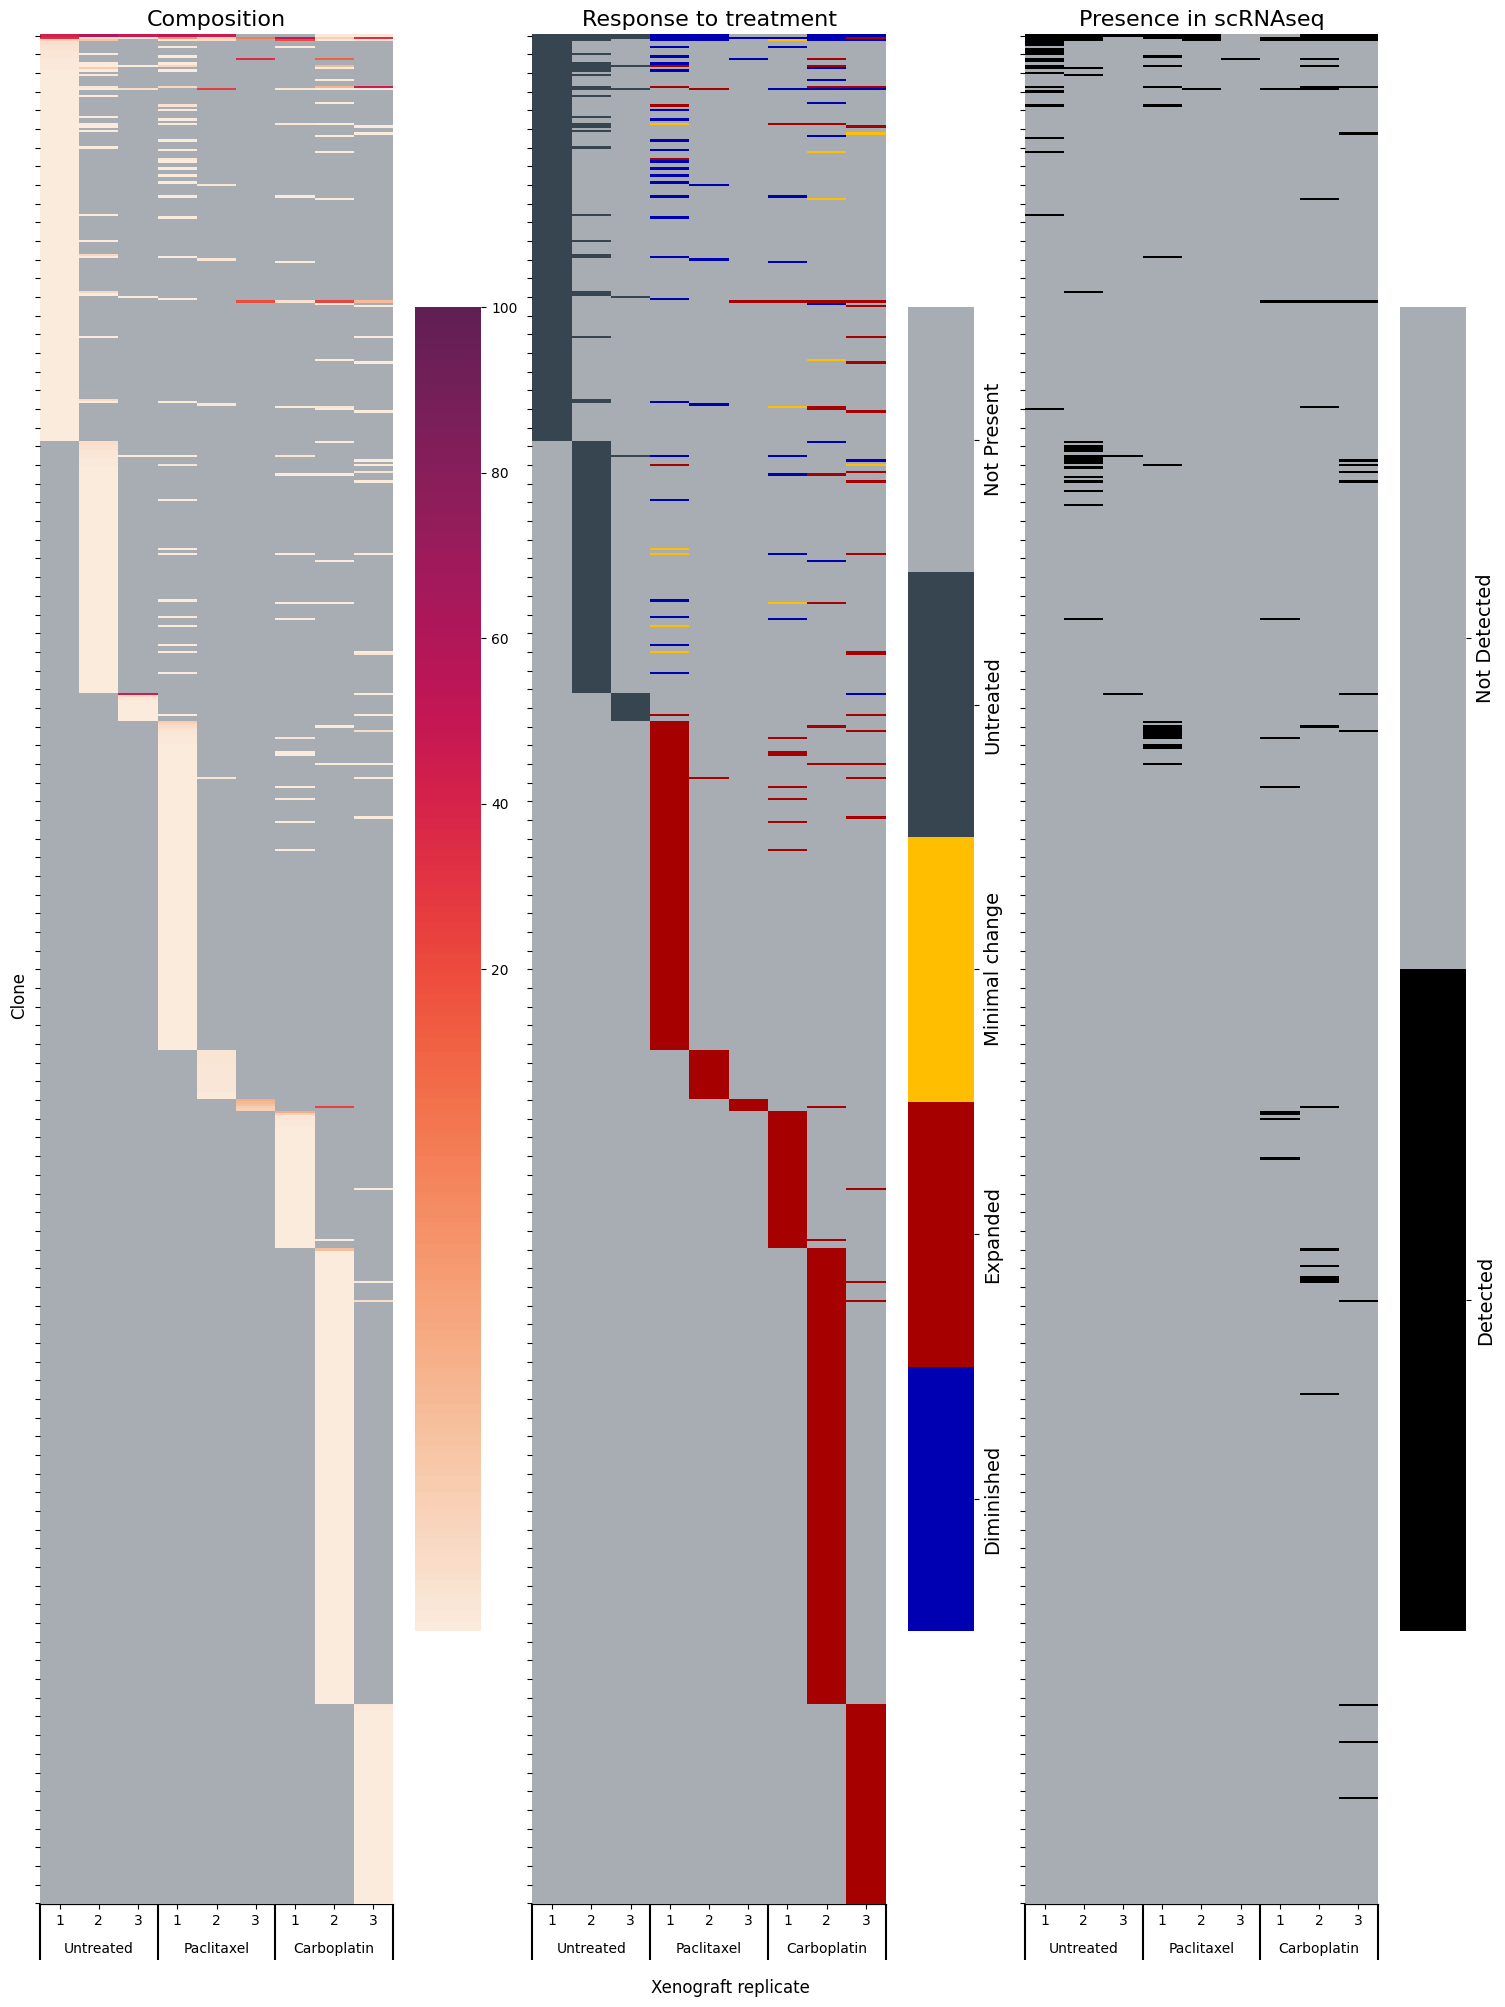

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/519926874.py:101: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=responses.replace(response_to_int), cmap=colormap_response, ax=axes[1])
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/519926874.py:102: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=RNApresence.replace(RNA_to_int), cmap=colormap_RNA, ax=axes[2])


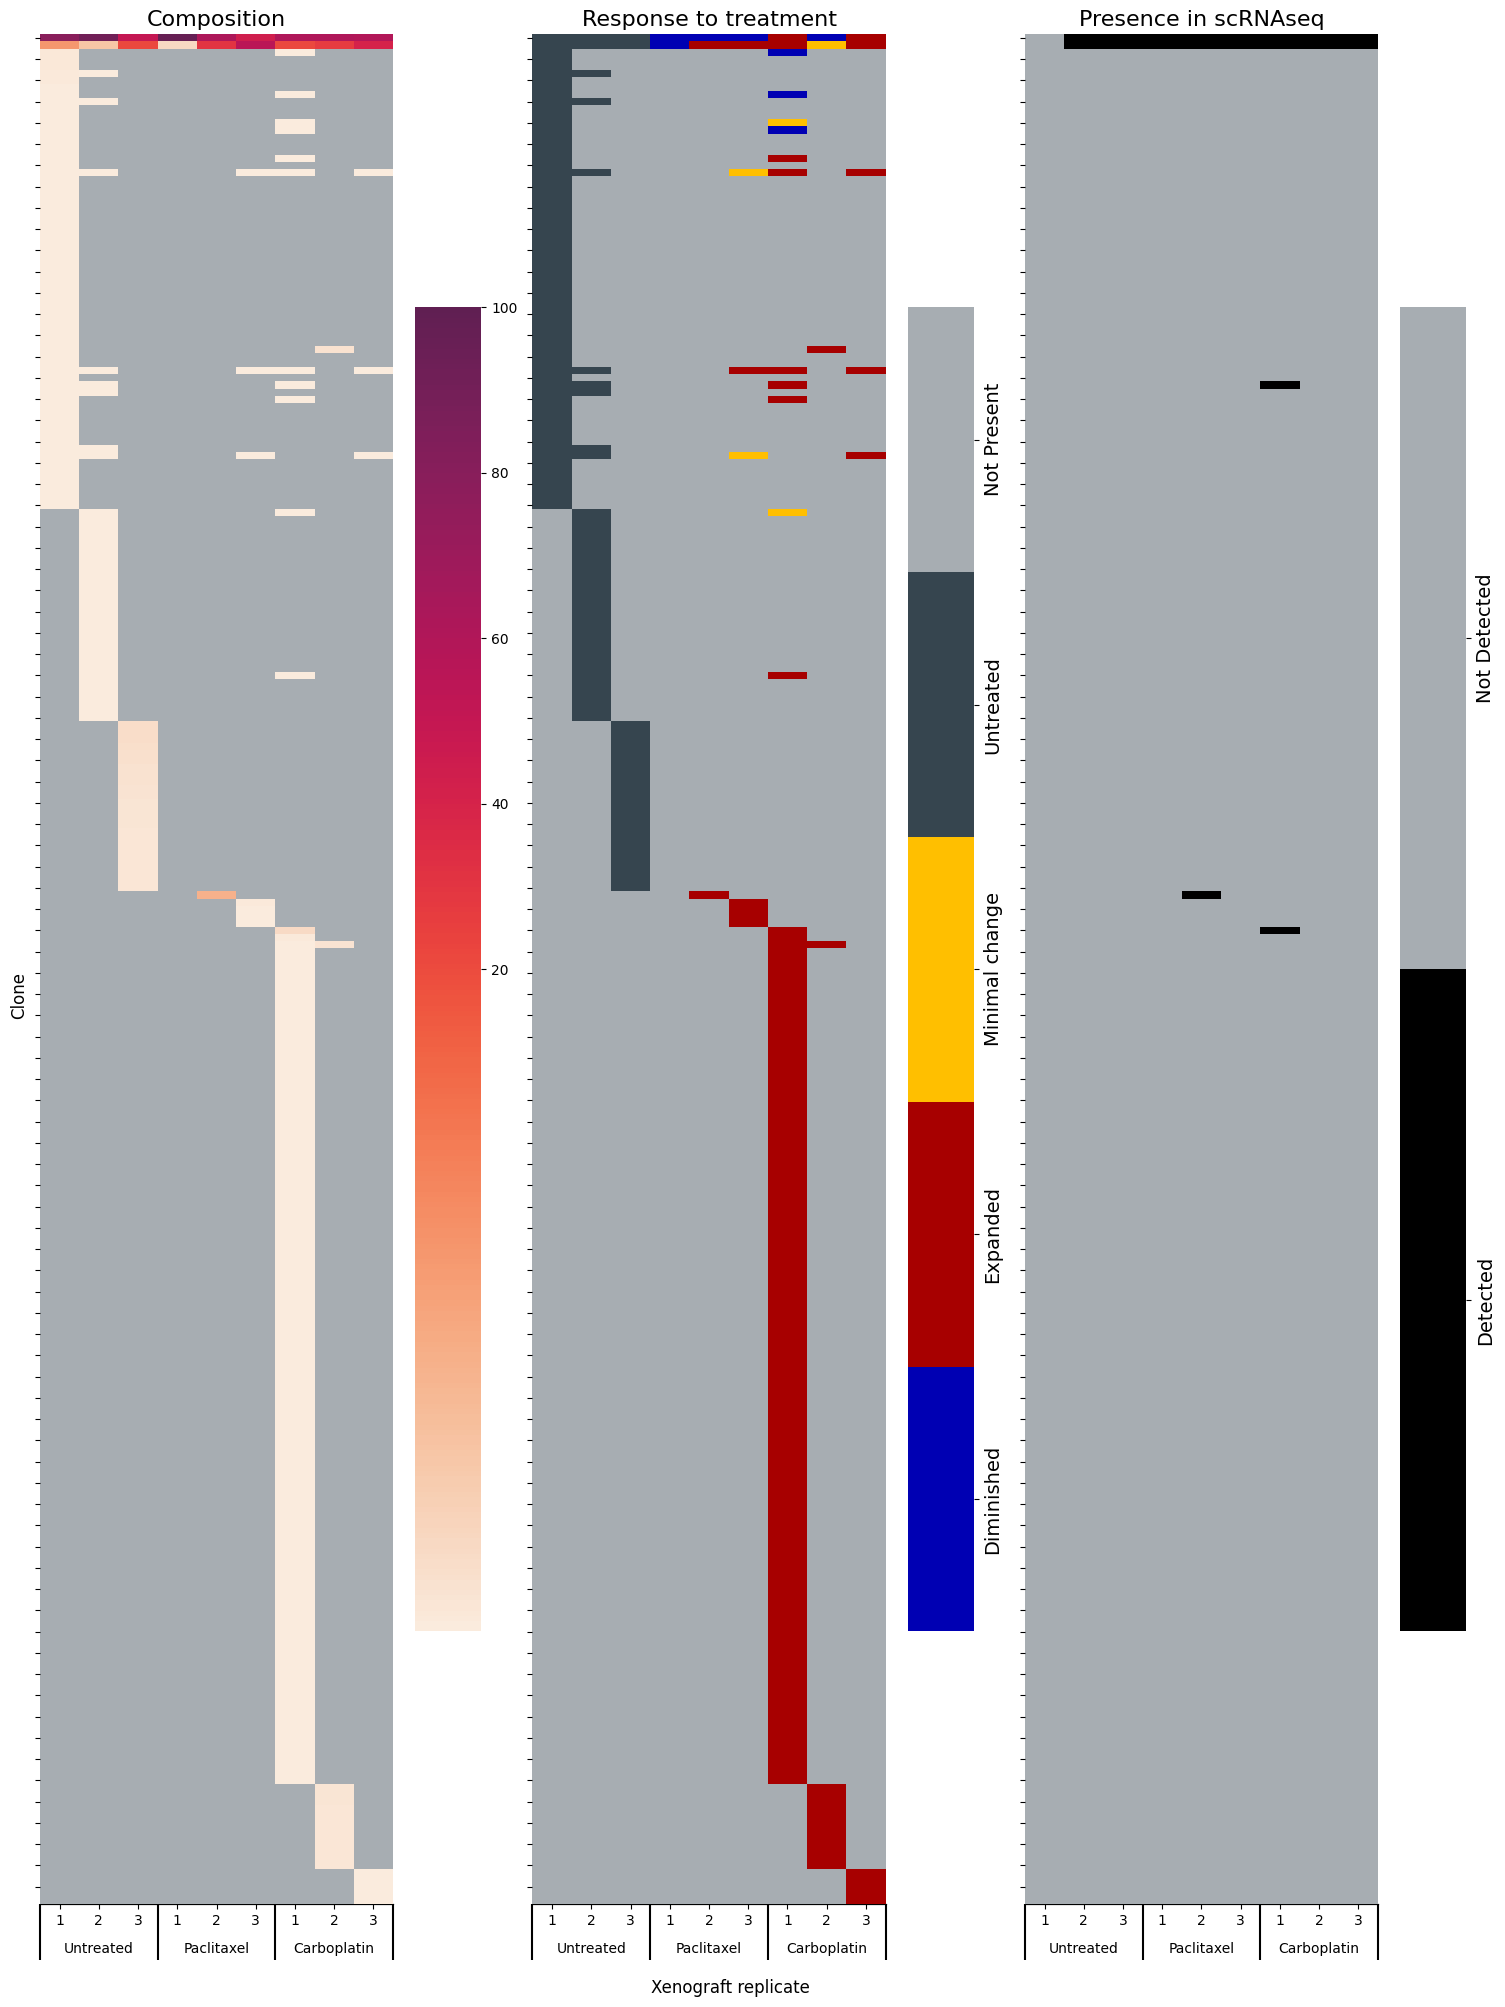

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/519926874.py:101: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=responses.replace(response_to_int), cmap=colormap_response, ax=axes[1])
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/519926874.py:102: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=RNApresence.replace(RNA_to_int), cmap=colormap_RNA, ax=axes[2])


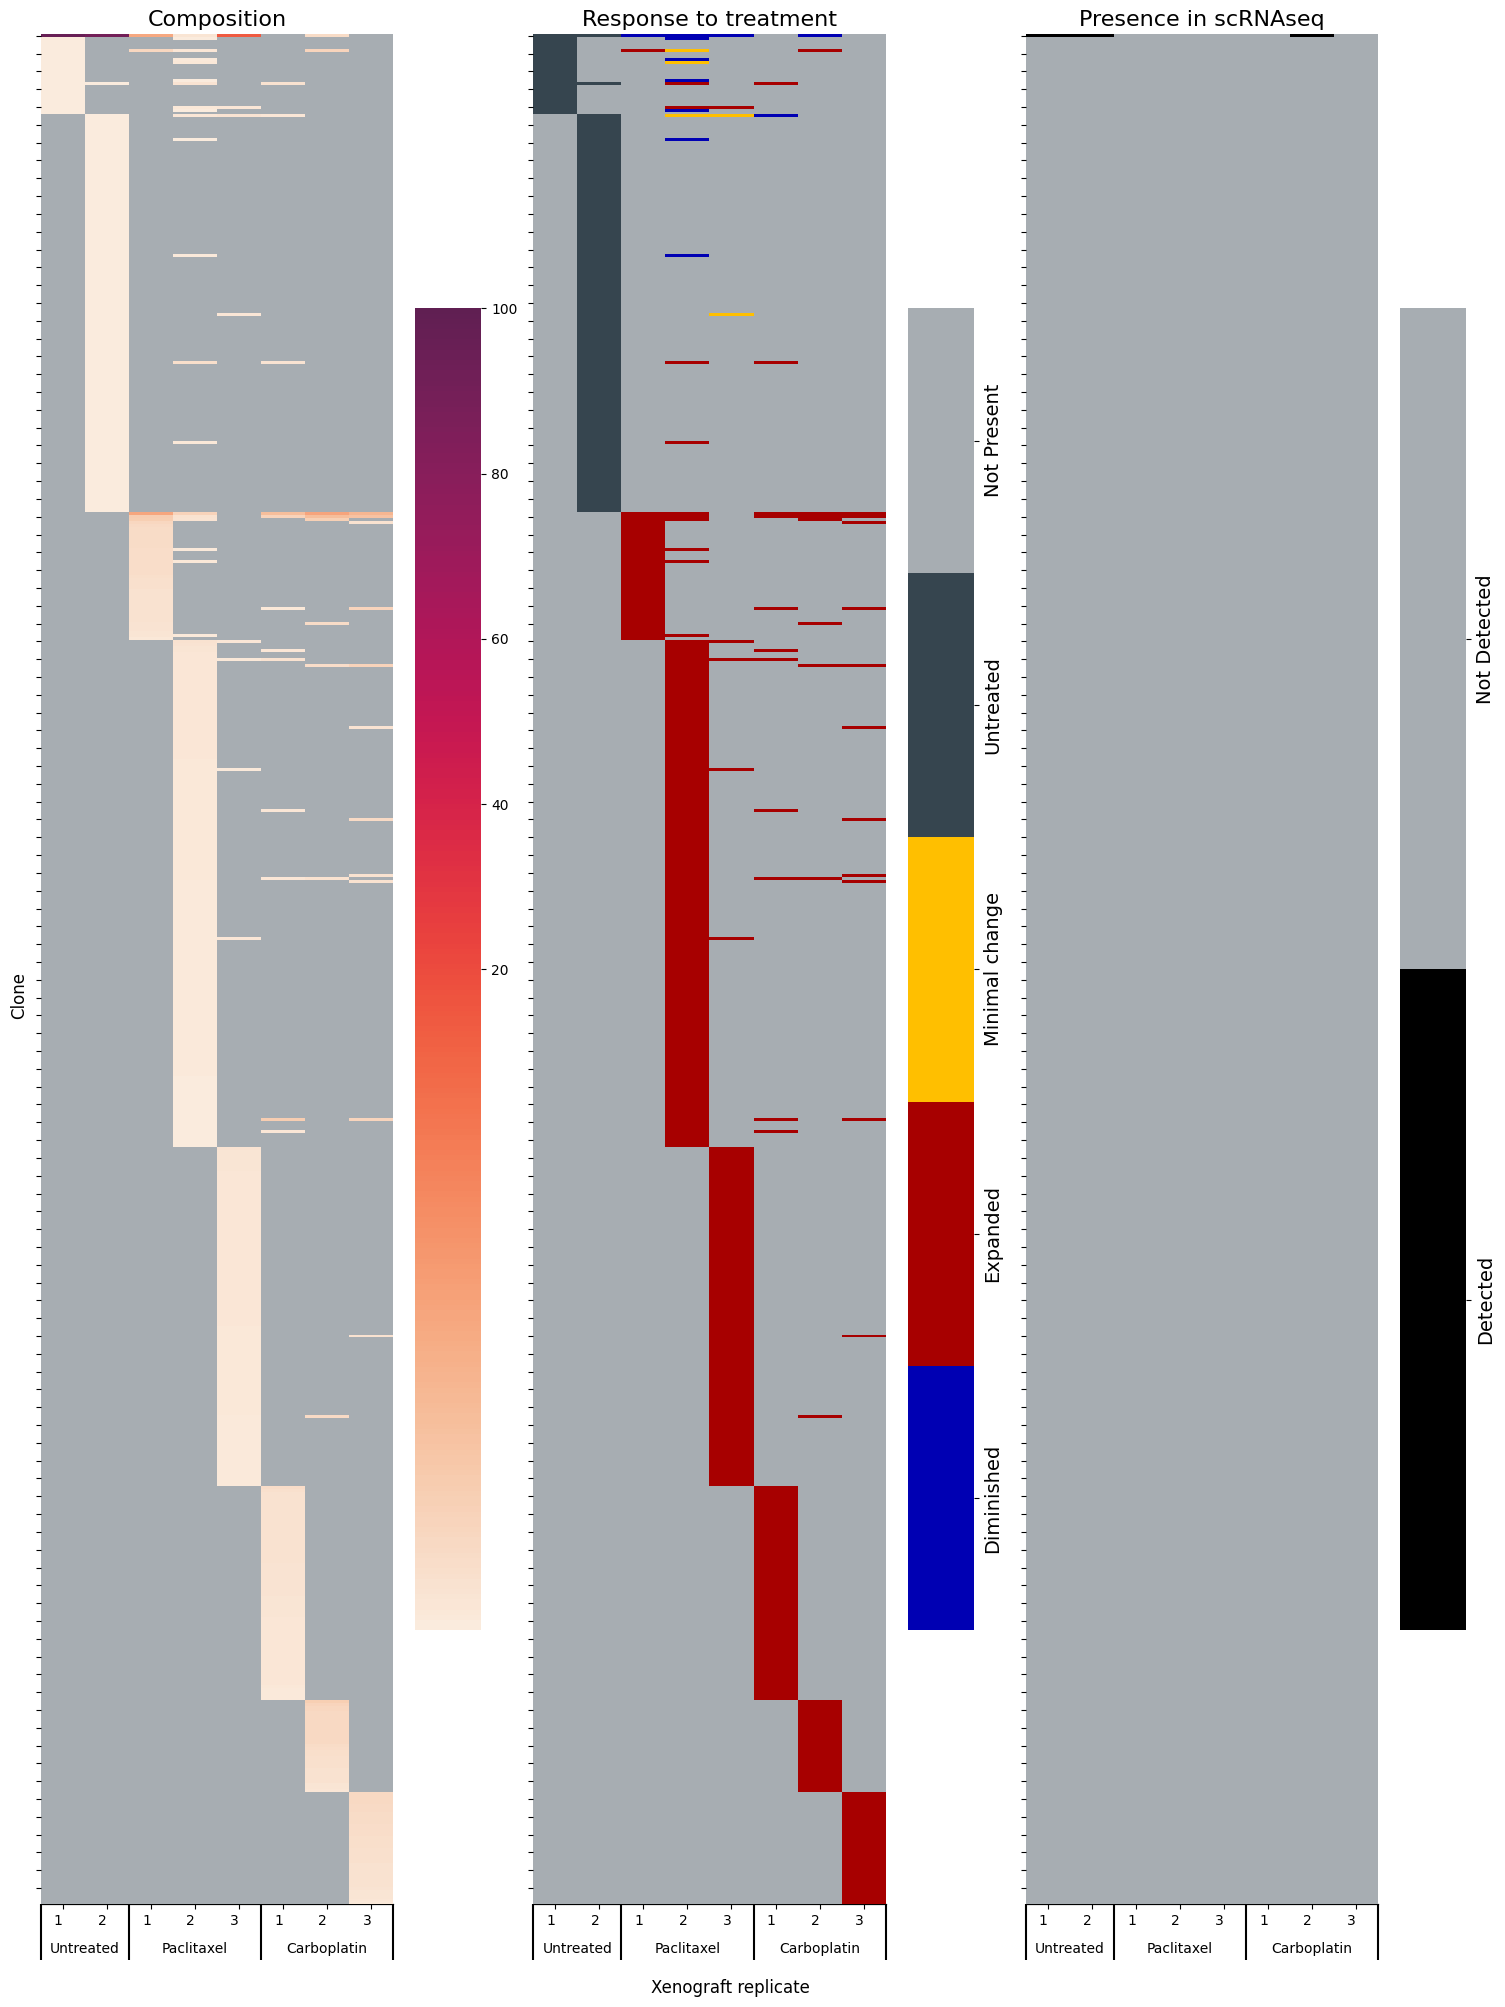

STG201
Cohort mouse
Paclitaxel 2    0.031044
dtype: float64


/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/519926874.py:101: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=responses.replace(response_to_int), cmap=colormap_response, ax=axes[1])
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/519926874.py:102: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=RNApresence.replace(RNA_to_int), cmap=colormap_RNA, ax=axes[2])


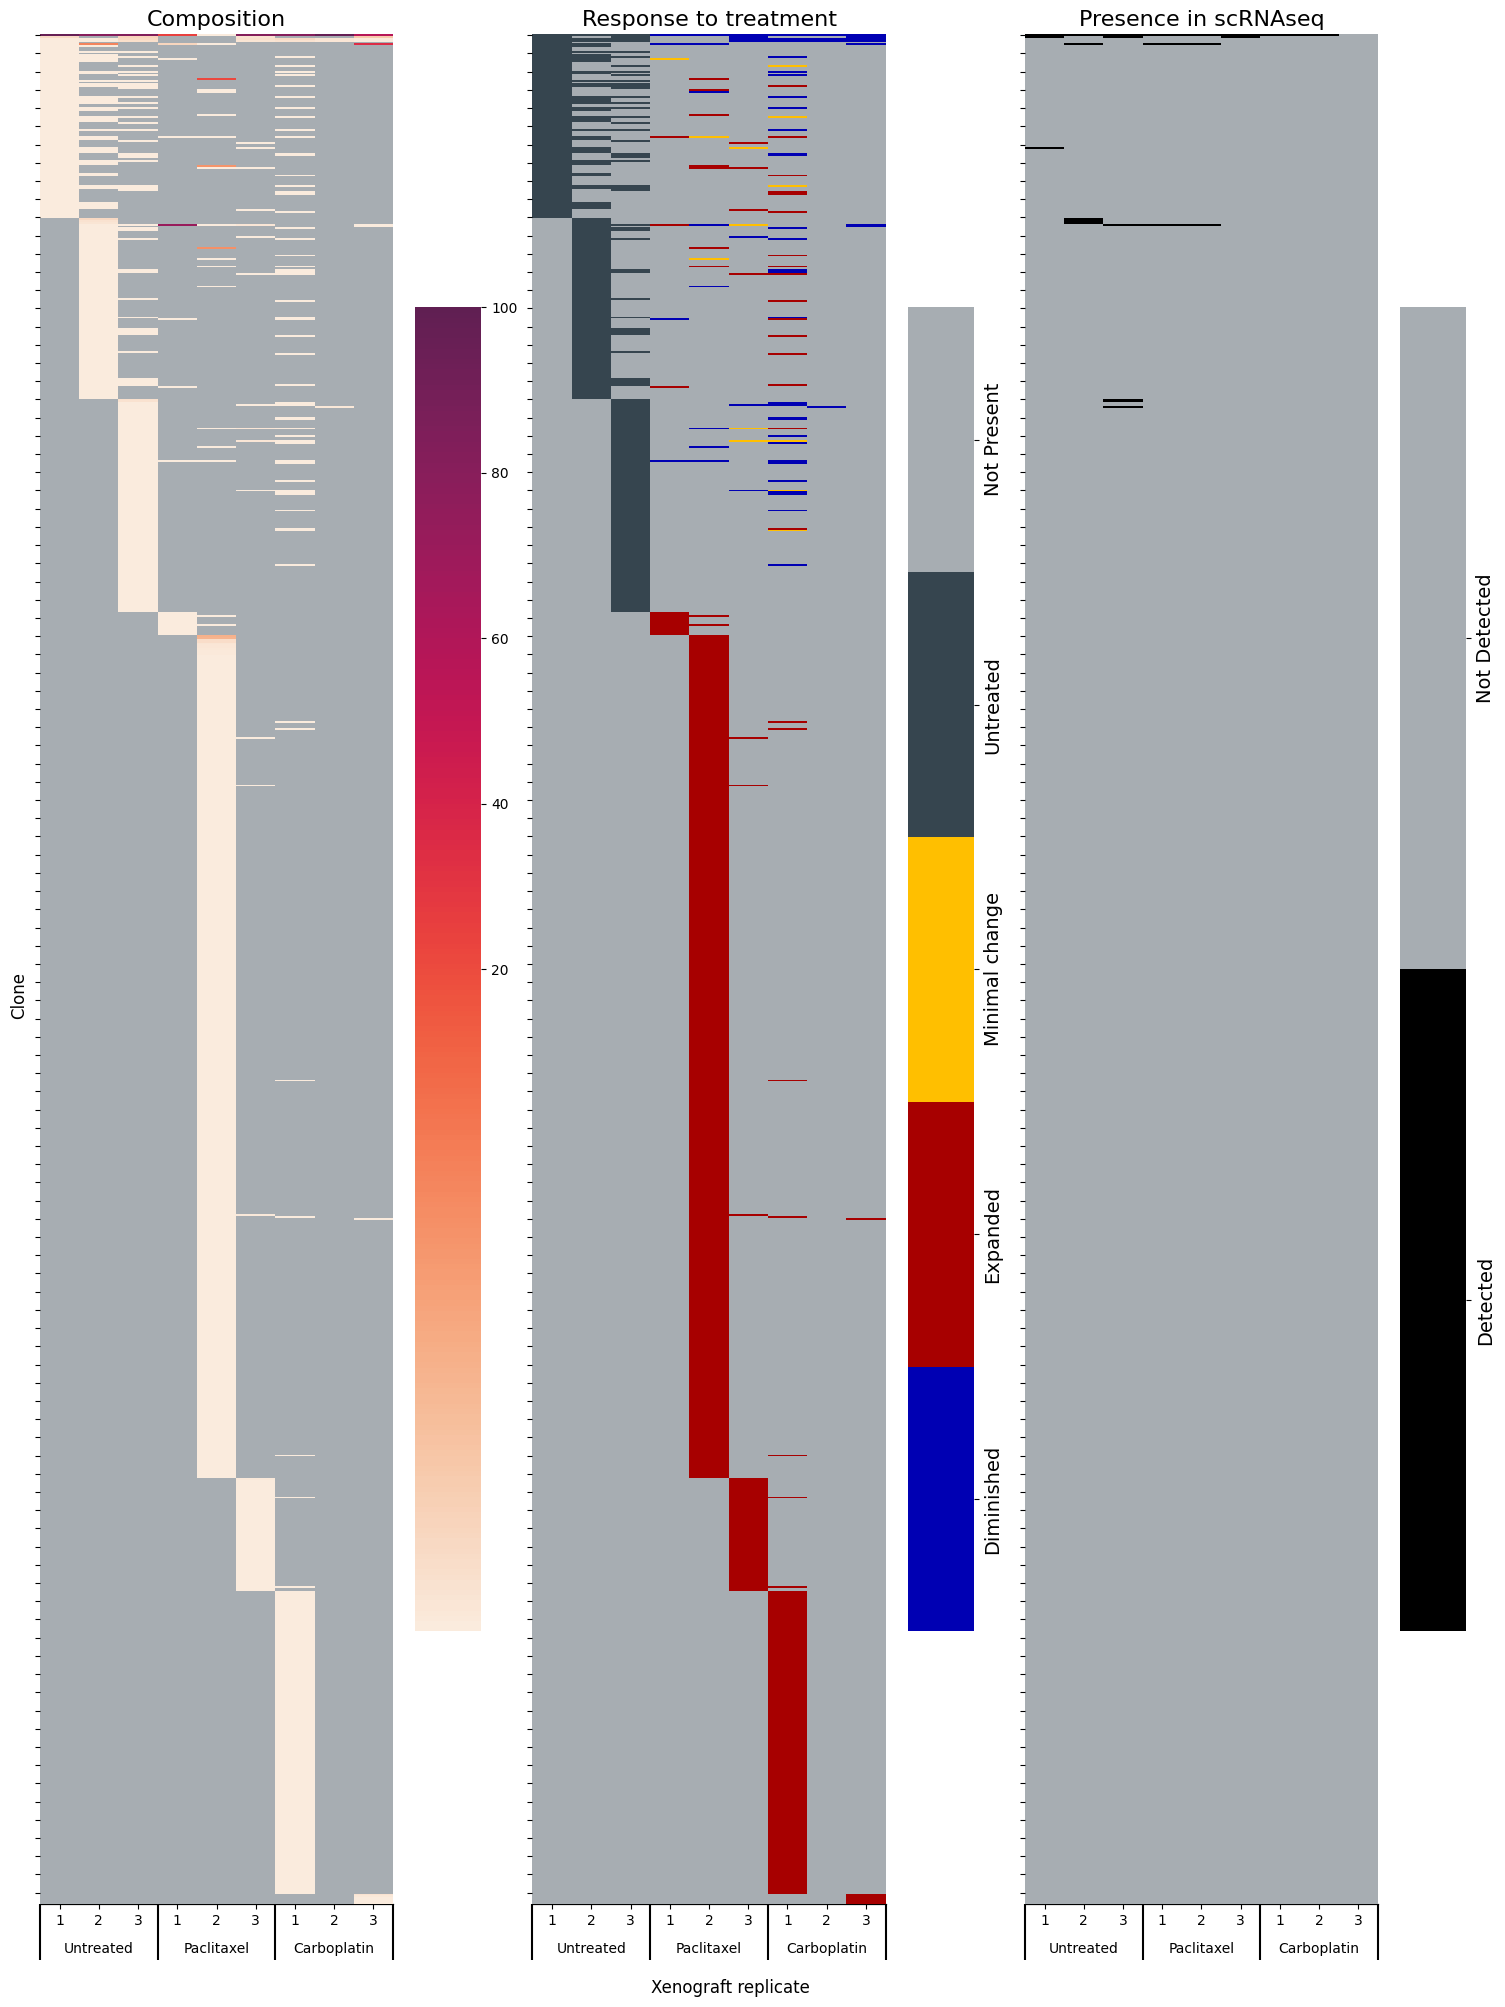

In [9]:
# NOTE: This accounting of scRNAseq presence is correct

# Graph heatmaps of shared and all barcodes in each tumor by the percent they make up in the tumor
# Set up dictionary to associate mouse designations with arbitrary mouse numbers (1-3)
mice = full_data.drop_duplicates(subset=["Mouse"])
mice["Sample"] = mice["Tumor"] + "_" + mice["Mouse"] + "_" + mice["Cohort"]
mice = mice[["Sample", "Mouse num"]].set_index("Sample").rename_axis(None, axis=1).to_dict()["Mouse num"]
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

sns.reset_defaults()

# Iterate through models
for key, val in clonal_comp_for_bargraph_treated_response.items():
    # Set up plot
    fig, axes = plt.subplots(1, 3, figsize=(15,20))

    # Set up data structure with percent composition and response to treatment
    df = pd.DataFrame(val)
    if key == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    df = df.sort_values(["Cohort", "Mouse", "Percent"], ascending = [False, True, False]).reset_index(drop=True)
    df["Cohort mouse"] = df["Cohort"] + " " + df["Mouse"].astype("str")

    # Get scRNAseq barcodes
    df["scRNAseq"] = "Not Detected"
    for file in scRNA_bc_files:
        file_split = file.split("_")
        if file_split[0] == key:
            cohort_mouse = f'{file_split[2]} {mice["_".join(file_split[0:3])]}'
            temp_df = pd.read_csv(f"{scRNA_bc_path}/{file}")
            temp_df = temp_df.loc[temp_df["barcode"] != "None"].drop_duplicates(subset=["barcode"])
            bcs = temp_df["barcode"].dropna().tolist()
            if len(bcs) > 0:
                for barcode in bcs:
                    for i, row in df.iterrows():
                        if row["Barcode"] == barcode and row["Cohort mouse"] == cohort_mouse:
                            df.at[i, "scRNAseq"] = "Detected"
    # Set up data structures and organize
    pivot_df = df[["Cohort mouse", "Barcode", "Percent"]]
    pivot_df = pivot_df.pivot(index='Barcode', columns='Cohort mouse', values='Percent').fillna(0)

    pivot_response = df[["Cohort mouse", "Barcode", "Response"]]
    pivot_response = pivot_response.pivot(index='Barcode', columns='Cohort mouse', values='Response').fillna("Not Present")

    pivot_RNApresence = df[["Cohort mouse", "Barcode", "scRNAseq"]]
    pivot_RNApresence = pivot_RNApresence.pivot(index='Barcode', columns='Cohort mouse', values='scRNAseq').fillna("Not Detected")

    response_to_int = {'Diminished': 0,
                    'Expanded': 1,
                    'Minimal change': 2,
                    "Untreated": 3,
                    "Not Present": 4}
    RNA_to_int = {"Detected": 0, 
                  "Not Detected": 1}
    
    # Sort percent dataframe and merge with the others so they're sorted too
    if key != "STG139":
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)
    else:
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)

    ordered_responses = pd.merge(pivot_df, pivot_response, how="inner", left_index=True, right_index=True)

    ordered_scRNA = pd.merge(pivot_df, pivot_RNApresence, how="inner", left_index=True, right_index=True)
    
    if key == "STG139":
        percent_comp = ordered_responses[['Untreated 1_x', 'Untreated 2_x', 'Paclitaxel 1_x', 'Paclitaxel 2_x', 'Paclitaxel 3_x', 'Carboplatin 1_x', 'Carboplatin 2_x', 'Carboplatin 3_x']]
        percent_comp = percent_comp.rename(columns = {'Untreated 1_x': "Untreated 1", 'Untreated 2_x': "Untreated 2", 'Paclitaxel 1_x': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_x': "Paclitaxel 3", 'Carboplatin 1_x': "Carboplatin 1", 'Carboplatin 2_x': "Carboplatin 2", 'Carboplatin 3_x': "Carboplatin 3"}).reset_index(drop=True)

        responses = ordered_responses[['Untreated 1_y', 'Untreated 2_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        responses = responses.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)

        RNApresence = ordered_scRNA[['Untreated 1_y', 'Untreated 2_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        RNApresence = RNApresence.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)

    else:
        percent_comp = ordered_responses[['Untreated 1_x', 'Untreated 2_x', 'Untreated 3_x', 'Paclitaxel 1_x', 'Paclitaxel 2_x', 'Paclitaxel 3_x', 'Carboplatin 1_x', 'Carboplatin 2_x', 'Carboplatin 3_x']]
        percent_comp = percent_comp.rename(columns = {'Untreated 1_x': "Untreated 1", 'Untreated 2_x': "Untreated 2", 'Untreated 3_x': "Untreated 3", 'Paclitaxel 1_x': "Paclitaxel 1", 'Paclitaxel 2_x': "Paclitaxel 2", 'Paclitaxel 3_x': "Paclitaxel 3", 'Carboplatin 1_x': "Carboplatin 1", 'Carboplatin 2_x': "Carboplatin 2", 'Carboplatin 3_x': "Carboplatin 3"}).reset_index(drop=True)

        responses = ordered_responses[['Untreated 1_y', 'Untreated 2_y', 'Untreated 3_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        responses = responses.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Untreated 3_y': "Untreated 3", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)

        RNApresence = ordered_scRNA[['Untreated 1_y', 'Untreated 2_y', 'Untreated 3_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        RNApresence = RNApresence.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Untreated 3_y': "Untreated 3", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)

    if key == "STG201":
        print(key)
        print(percent_comp[percent_comp["Paclitaxel 2"] > 0][["Paclitaxel 2"]].min())

    # Set up heatmap parameters
    vmin, vmax = 0.000000000000000000000000001, 100
    vcenter = 20
    normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
    colormap_percent = ListedColormap(mpl.colormaps["rocket_r"](np.linspace(0, 0.75, 256)))
    colormap_percent.set_under(color="#a7adb2")
    colormap_response = sns.color_palette(["#0000b3", "#a70000", "#FFBF00", "#36454F", "#a7adb2"], 5)
    colormap_RNA = sns.color_palette(["#000000", "#a7adb2"], 2)
    
    # Construct heatmaps for total and shared clones
    sns.heatmap(data=percent_comp, cmap=colormap_percent, ax=axes[0], norm=normalize, vmin=0, vmax=100)
    sns.heatmap(data=responses.replace(response_to_int), cmap=colormap_response, ax=axes[1])
    sns.heatmap(data=RNApresence.replace(RNA_to_int), cmap=colormap_RNA, ax=axes[2])
    
    # Set up plot parameters
    axes[0].set_title(f"Composition", fontsize=16)
    axes[0].set(yticklabels=[])
    axes[0].set(xlabel=None, ylabel=None)
    axes[1].set_title(f"Response to treatment", fontsize=16)
    axes[1].set(yticklabels=[]) 
    axes[1].set(xlabel=None, ylabel=None)
    axes[2].set_title(f"Presence in scRNAseq", fontsize=16)
    axes[2].set(yticklabels=[])
    axes[2].set(xlabel=None, ylabel=None) 

    # Modify colorbars for response and scRNAseq heat maps
    colorbar2 = axes[1].collections[0].colorbar 
    r = colorbar2.vmax - colorbar2.vmin 
    colorbar2.set_ticks([colorbar2.vmin + r / 5 * (0.5 + i) for i in range(5)])
    colorbar2.set_ticklabels(list(response_to_int.keys()), fontsize=14, rotation = 90)
    for label in colorbar2.ax.get_yticklabels():
        label.set_verticalalignment('center')

    colorbar3 = axes[2].collections[0].colorbar 
    r = colorbar3.vmax - colorbar3.vmin 
    colorbar3.set_ticks([colorbar3.vmin + r / 2 * (0.5 + i) for i in range(2)])
    colorbar3.set_ticklabels(list(RNA_to_int.keys()), fontsize=14, rotation = 90)
    for label in colorbar3.ax.get_yticklabels():
        label.set_verticalalignment('center')

    # Set up primary and secondary x-axis labels
    for ax in axes:
        if key == "STG139":
            ax.set_xticklabels(labels=["1", "2", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10, ha="right")

            # label the classes:
            sec = ax.secondary_xaxis(location=0)
            sec.set_xticks([1, 3.5, 6.5], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
            sec.tick_params('x', length=0)

            # lines between the classes:
            sec2 = ax.secondary_xaxis(location=0)
            sec2.set_xticks([0, 2, 5, 8], labels=[])
            sec2.tick_params('x', length=40, width=1.5)

        else:
            ax.set_xticklabels(labels=["1", "2", "3", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

            # label the classes:
            sec = ax.secondary_xaxis(location=0)
            sec.set_xticks([1.5, 4.5, 7.5], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
            sec.tick_params('x', length=0)

            # lines between the classes:
            sec2 = ax.secondary_xaxis(location=0)
            sec2.set_xticks([0, 3, 6, 9], labels=[])
            sec2.tick_params('x', length=40, width=1.5)

    fig.text(0.48, 0.001, "Xenograft replicate", ha="center", fontsize=12)
    fig.text(0, 0.5, "Clone", rotation="vertical", va="center", fontsize=12)
    fig.tight_layout(rect=[0.01, 0.01, 1, 1])
    plt.savefig(f"../visualizations/amplicon/amplicon_{key}_clonalComposition_responseToTreatment_scRNAseqPresence.svg")
    plt.show()

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1580463335.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), size=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1580463335.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), size=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1580463335.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), size=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1580463335.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.se

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Untreated vs. Paclitaxel: Mann-Whitney-Wilcoxon test two-sided, P_val:1.150e-01 U_stat=3.169e+04
Paclitaxel vs. Carboplatin: Mann-Whitney-Wilcoxon test two-sided, P_val:2.230e-23 U_stat=1.446e+04
Untreated vs. Carboplatin: Mann-Whitney-Wilcoxon test two-sided, P_val:3.155e-19 U_stat=6.123e+03
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Untreated vs. Paclitaxel: Mann-Whitney-Wilcoxon test two-sided, P_val:2.404e-47 U_stat=1.806e+05
Paclitaxel vs. Carboplatin: Mann-Whitney-Wilcoxon test two-sided, P_val:1.127e-78 U_stat=1.203e+04
Untreated vs. Carboplatin: Mann-Whitney-Wilcoxon test two-sided, P_val:2.309e-05 U_stat=3.897e+04
p-value annotation legend:
 

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1580463335.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), size=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1580463335.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), size=9)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Untreated vs. Paclitaxel: Mann-Whitney-Wilcoxon test two-sided, P_val:6.320e-02 U_stat=6.490e+02
Paclitaxel vs. Carboplatin: Mann-Whitney-Wilcoxon test two-sided, P_val:1.193e-01 U_stat=1.402e+03
Untreated vs. Carboplatin: Mann-Whitney-Wilcoxon test two-sided, P_val:9.805e-05 U_stat=7.827e+03


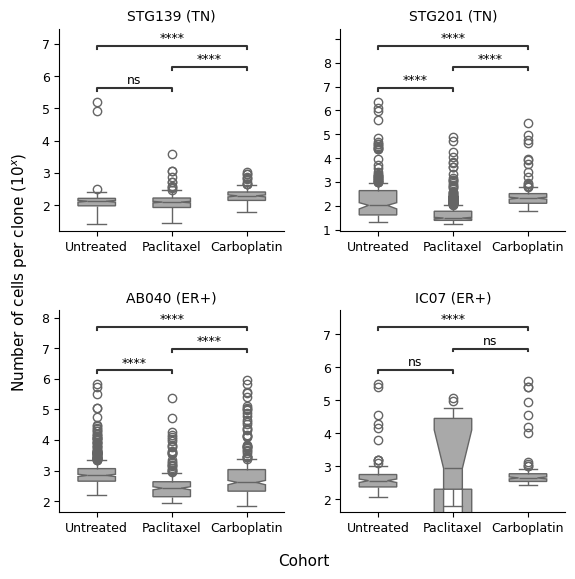

In [10]:
# Box and whisker plot of clone sizes in each cohort for each mouse
## Shows changes in clonal composition
sns.reset_defaults()
# Set up figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(6,6))
# Keep track of subplots
counter = 0
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}
model_order = ["STG139", "STG201", "AB040", "IC07"]

def log_tick_formatter(val, pos):
    return f'{int(np.log10(val))}'

# Iterate through axes
for i, ax in enumerate(axes.flatten()):
    model = model_order[i]
    df = pd.DataFrame(clonal_comp_for_bargraph_treated_response[model]).sort_values(["Cohort"], ascending=False)
    if model == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    strip_args = {
        "x": "Cohort",
        "y": "Cell counts",
        "data": df,
        "zorder": 0.5,
        "order": ["Untreated", "Paclitaxel", "Carboplatin"],
        "dodge": True
    }
    sns.set_context(rc={"font.size":9,"axes.titlesize":10,"axes.labelsize":8, "xtick.labelsize":8, "ytick.labelsize":8}) 
    sns.boxplot(
        ax=ax,
        x="Cohort",
        y="Cell counts",
        data=df,
        width=0.5,
        order=["Untreated", "Paclitaxel", "Carboplatin"],
        color="darkgrey",
        notch=True
    )
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(log_tick_formatter))
    ax.yaxis.minorticks_off()
    ax.set_title(f"{model} ({model_type[model]})", fontsize=10)
    ax.set(xlabel=None, ylabel=None)
    ax.set_xticklabels(ax.get_xticklabels(), size=9)
    ax.set_yticklabels(ax.get_yticklabels(), size=9)
    ax.set_xlim(-0.5, 2.5)
    annot = Annotator(
        ax=ax,
        pairs=[
            ("Untreated", "Carboplatin"),
            ("Untreated", "Paclitaxel"),
            ("Carboplatin", "Paclitaxel")
        ],
        **strip_args,
        plot="stripplot"
    )
    annot.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=2) 
    annot.apply_test().annotate() 
fig.text(0.5, 0.01, "Cohort", ha="center", fontsize=11)
fig.text(0.01, 0.5, "Number of cells per clone (10$^{x}$)", rotation="vertical", va="center", fontsize=11)
sns.despine()
plt.rcParams['font.family'] = 'Arial'
plt.tight_layout(pad=3)
plt.savefig(f"../visualizations/amplicon/amplicon_boxplot_clone_size.svg")
plt.show()

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:22: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1.5}` instead.

  sns.barplot(
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), size=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), size=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:22: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1.5}` instead.

  sns.barplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Untreated vs. Paclitaxel: t-test independent samples, P_val:4.962e-02 t=1.968e+00
Paclitaxel vs. Carboplatin: t-test independent samples, P_val:8.181e-05 t=-3.970e+00
Untreated vs. Carboplatin: t-test independent samples, P_val:1.948e-01 t=1.299e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Untreated vs. Paclitaxel: t-test independent samples, P_val:2.531e-02 t=2.240e+00
Paclitaxel vs. Carboplatin: t-test independent samples, P_val:2.368e-02 t=-2.266e+00
Untreated vs. Carboplatin: t-test independent samples, P_val:2.241e-01 t=1.217e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), size=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), size=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:22: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1.5}` instead.

  sns.barplot(
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),

Paclitaxel vs. Carboplatin: t-test independent samples, P_val:1.213e-01 t=-1.551e+00
Untreated vs. Carboplatin: t-test independent samples, P_val:7.237e-01 t=-3.536e-01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Untreated vs. Paclitaxel: t-test independent samples, P_val:5.523e-02 t=-1.933e+00
Paclitaxel vs. Carboplatin: t-test independent samples, P_val:1.449e-01 t=1.464e+00
Untreated vs. Carboplatin: t-test independent samples, P_val:6.824e-01 t=-4.097e-01


/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), size=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/600815880.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), size=9)


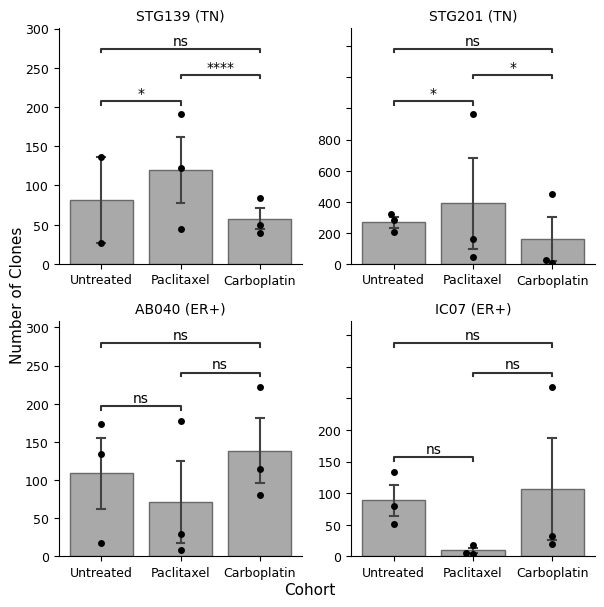

In [11]:
# Box and whisker plot of total number of clones by cohort
## Shows changes in heterogeneity
sns.reset_defaults()

# Set up figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
# Keep track of subplots
counter = 0
order=["Untreated", "Paclitaxel", "Carboplatin"]
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}
model_order = ["STG139", "STG201", "AB040", "IC07"]

# Iterate through axes
for i, ax in enumerate(axes.flatten()):
    model = model_order[i]
    df = pd.DataFrame(clonal_comp_for_bargraph_treated_response[model]).sort_values(["Cohort"], ascending=False)
    if model == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    grouped = df.groupby(["Cohort", "Mouse"]).count().reset_index()
    pivot = grouped.pivot(index="Mouse", columns='Cohort', values='Cell counts')
    
    sns.barplot(
        ax=ax,
        x="Cohort",
        y="Num clones",
        data=grouped,
        capsize=0.1,
        errwidth=1.5,
        order=order,
        errorbar="se",
        color="darkgrey",
        edgecolor='dimgrey'
    )
    sns.swarmplot(
        ax=ax,
        x="Cohort",
        y="Num clones",
        data=grouped, 
        color="Black",
        order=order
    )
    annot = Annotator(
        ax,
        data=df,
        x="Cohort",
        y="Cell counts",
        pairs=[
            ("Untreated", "Carboplatin"),
            ("Untreated", "Paclitaxel"),
            ("Carboplatin", "Paclitaxel")
        ],
        order=order
    )
    annot.configure(test='t-test_ind', text_format='star', loc='inside', verbose=2)
    annot.apply_test().annotate()
    ax.set_title(f"{model} ({model_type[model]})", fontsize=10)
    ax.set(xlabel=None, ylabel=None)
    ax.set_xticklabels(ax.get_xticklabels(), size=9)
    ax.set_yticklabels(ax.get_yticklabels(), size=9)
fig.text(0.5, 0.0002, "Cohort", ha="center", fontsize=11)
fig.text(0.00008, 0.5, "Number of Clones", rotation="vertical", va="center", fontsize=11)
sns.despine()
plt.tight_layout() 
plt.savefig(f"../visualizations/amplicon/amplicon_clone_number.svg")
plt.show()

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/2031251472.py:81: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=ordered_responses.replace(amp_to_int),
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/2031251472.py:81: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sns.heatmap(data=ordered_responses.replace(amp_to_int),
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/2031251472.py:81: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in 

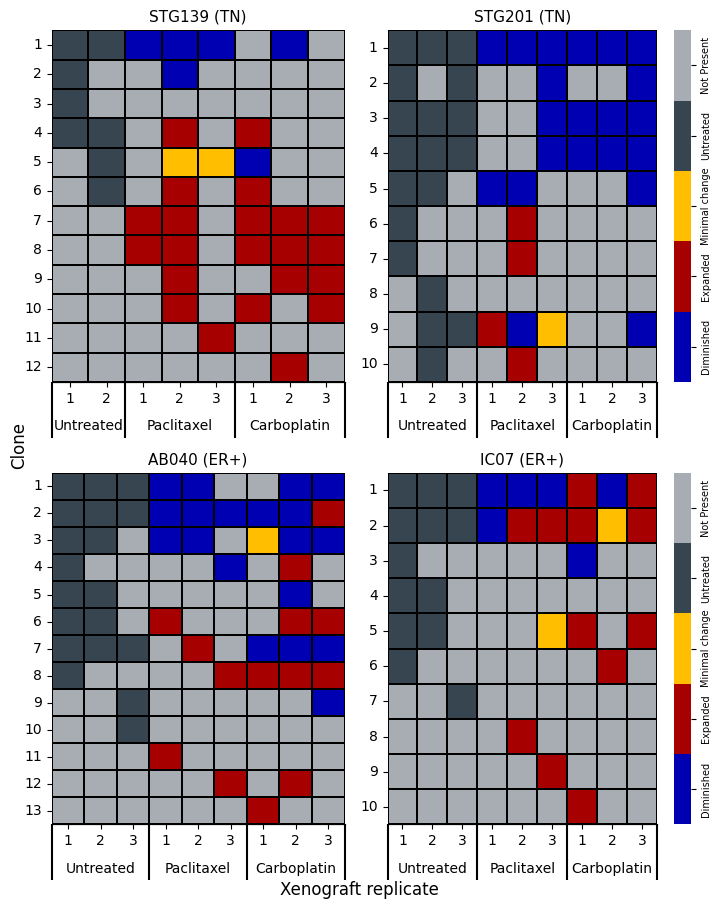

In [12]:
# Graph heatmaps of top 5 most populous clones in each tumor by the percent they make up of the tumor
## NOTE: If any of the top 3 are in another column, there will be fewer rows in the final heatmap

num_top_clones = 3
dict_of_dfs_heatmap = {}
mice = [1, 2, 3]
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

plt.rcdefaults()

for key, val in clonal_comp_for_bargraph_treated_response.items():
    df = pd.DataFrame(val)
    if key == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    
    # Adjust dataframe
    top_barcodes = []
    for cohort in df["Cohort"].unique():
        for mouse in range(1, 4):
            curr_df = df.copy()
            curr_df = curr_df.loc[(curr_df["Cohort"] == cohort) & (curr_df["Mouse"] == mouse)].sort_values("Cell counts", ascending=False).reset_index(drop=True)
            top_clones = curr_df.head(num_top_clones)
            barcodes = top_clones["Barcode"].to_list()
            top_barcodes.extend(barcodes)
    
    top_barcodes = list(set(top_barcodes))
    top_clones_df = df.loc[df["Barcode"].isin(top_barcodes)]
    top_clones_df = top_clones_df.sort_values(["Cohort", "Mouse", "Cell counts"], ascending=[False, True, False]).reset_index(drop=True)
    
    final_df = top_clones_df.sort_values(["Cohort", "Mouse", "Percent"], ascending = [False, True, False]).reset_index(drop=True)
    final_df["Cohort mouse"] = final_df["Cohort"] + " " + final_df["Mouse"].astype("str")

    dict_of_dfs_heatmap[key] = final_df

key_order = ["STG139", "STG201", "AB040", "IC07"]
sorted_dict = {}
for key in key_order:
    if key in dict_of_dfs_heatmap:  
        sorted_dict[key] = dict_of_dfs_heatmap[key]

# Set up figure with subplots
fig, ax = plt.subplots(2, 2, figsize=(7.3, 9), width_ratios=[1, 1.15])
# Keep track of subplots
counter = 0
# Iterate through models
for axis, (key, val) in zip(ax.flatten(), sorted_dict.items()):
    amp_to_int = {'Diminished': 0,
                    'Expanded': 1,
                    'Minimal change': 2,
                    "Untreated": 3,
                    "Not Present": 4}
    # Grab the data & organize
    pivot_df = val[["Cohort mouse", "Barcode", "Percent"]]
    pivot_df = pivot_df.pivot(index='Barcode', columns='Cohort mouse', values='Percent').fillna(0)
    pivot_responses = val[["Cohort mouse", "Barcode", "Response"]]
    pivot_responses = pivot_responses.pivot(index='Barcode', columns='Cohort mouse', values='Response').fillna("Not Present")
    if key != "STG139":
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)
    else:
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)
    ordered_responses = pd.merge(pivot_df, pivot_responses, how="inner", left_index=True, right_index=True)

    if key == "STG139":
        ordered_responses = ordered_responses[['Untreated 1_y', 'Untreated 2_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        ordered_responses = ordered_responses.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)
    else:
        ordered_responses = ordered_responses[['Untreated 1_y', 'Untreated 2_y', 'Untreated 3_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        ordered_responses = ordered_responses.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Untreated 3_y': "Untreated 3", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)
    
    ordered_responses.index = ordered_responses.index + 1

    colormap = sns.color_palette(["#0000b3", "#a70000", "#FFBF00", "#36454F", "#a7adb2"], 5)

    # Set up colorbar variable
    if axis in [ax[0, 1], ax[1, 1]]:
        cbar = True
    else:
        cbar = False
    
    # Construct heatmaps for total and shared clones
    sns.heatmap(data=ordered_responses.replace(amp_to_int), 
                cmap=colormap, 
                ax=axis, 
                cbar=cbar,
                linewidths=0.2,
                linecolor="black")
    
    # Set up plot parameters
    axis.set_title(f"{key} ({model_type[key]})", fontsize=11)
    if key == "STG139":
        axis.set_xticklabels(labels=["1", "2", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = axis.secondary_xaxis(location=0)
        sec.set_xticks([1, 3.5, 6.5], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = axis.secondary_xaxis(location=0)
        sec2.set_xticks([0, 2, 5, 8], labels=[])
        sec2.tick_params('x', length=40, width=1.5)

    else:
        axis.set_xticklabels(labels=["1", "2", "3", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = axis.secondary_xaxis(location=0)
        sec.set_xticks([1.5, 4.5, 7.5], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = axis.secondary_xaxis(location=0)
        sec2.set_xticks([0, 3, 6, 9], labels=[])
        sec2.tick_params('x', length=40, width=1.5)

    # Modify colorbars
    if axis in [ax[0, 1], ax[1, 1]]:
        colorbar = axis.collections[0].colorbar
        r = colorbar.vmax - colorbar.vmin
        colorbar.set_ticks([colorbar.vmin + r / 5 * (0.5 + i) for i in range(5)])
        colorbar.set_ticklabels(list(amp_to_int.keys()), fontsize=7, rotation=90)
        for label in colorbar.ax.get_yticklabels():
            label.set_verticalalignment('center')

    axis.set(xlabel=None, ylabel=None)
    axis.set_yticklabels(axis.get_yticklabels(), rotation=0, fontsize=10)
    
    counter += 1

fig.text(0.48, 0, "Xenograft replicate", ha="center", fontsize=12)
fig.text(0.001, 0.5, "Clone", rotation="vertical", va="center", fontsize=12)
fig.tight_layout()
plt.rcParams['font.family'] = 'Arial'
plt.savefig("../visualizations/amplicon/amplicon_heatmap_clonal_response_to_treatment.svg")
plt.show()

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/112560912.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mice["Sample"] = mice["Tumor"] + "_" + mice["Mouse"] + "_" + mice["Cohort"]


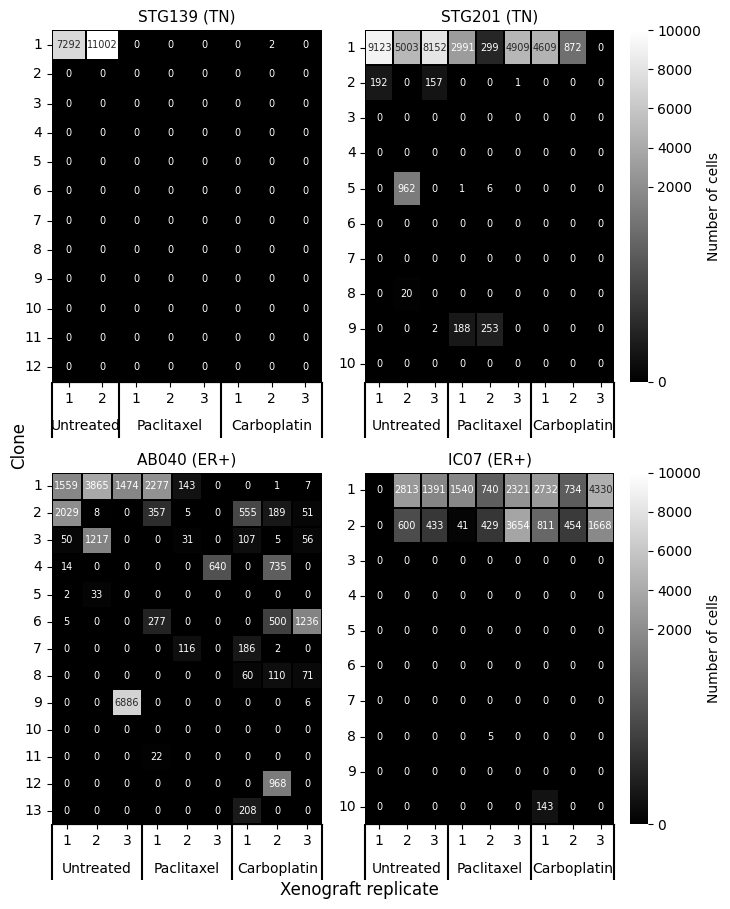

In [13]:
# Graph heatmaps of top 3 most prevalent clones in each tumor whether they're detected in scRNAseq
## NOTE: If any of the top 5 are in another column, there will be fewer rows in the final heatmap

num_top_clones = 3
dict_of_dfs_heatmap = {}
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

# Set up mice for scRNAseq info
mice = full_data.drop_duplicates(subset=["Mouse"])
mice["Sample"] = mice["Tumor"] + "_" + mice["Mouse"] + "_" + mice["Cohort"]
mice = mice[["Sample", "Mouse num"]].set_index("Sample").rename_axis(None, axis=1).to_dict()["Mouse num"]

sns.reset_defaults()

for key, val in clonal_comp_for_bargraph_treated_response.items():
    df = pd.DataFrame(val)
    if key == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    
    # Adjust dataframe
    top_barcodes = []
    for cohort in df["Cohort"].unique():
        for mouse in range(1, 4):
            curr_df = df.copy()
            curr_df = curr_df.loc[(curr_df["Cohort"] == cohort) & (curr_df["Mouse"] == mouse)].sort_values("Cell counts", ascending=False).reset_index(drop=True)
            top_clones = curr_df.head(num_top_clones)
            barcodes = top_clones["Barcode"].to_list()
            top_barcodes.extend(barcodes)
    
    top_barcodes = list(set(top_barcodes))
    top_clones_df = df.loc[df["Barcode"].isin(top_barcodes)]
    top_clones_df = top_clones_df.sort_values(["Cohort", "Mouse", "Cell counts"], ascending=[False, True, False]).reset_index(drop=True)
    
    final_df = top_clones_df.sort_values(["Cohort", "Mouse", "Percent"], ascending = [False, True, False]).reset_index(drop=True)
    final_df["Cohort mouse"] = final_df["Cohort"] + " " + final_df["Mouse"].astype("str")

    # Get scRNAseq presence/ absence
    final_df["scRNAseq"] = 0
    for file in scRNA_bc_files:
        file_split = file.split("_")
        if file_split[0] == key:
            if file_split[2] != "Primary":
                cohort_mouse = f'{file_split[2]} {mice["_".join(file_split[0:3])]}'
                bc_only_temp_df = pd.read_csv(f"{scRNA_bc_path}/{file}")
                bc_count = bc_only_temp_df["barcode"]
                bc_only_count = bc_only_temp_df["barcode"].value_counts()
                if bc_count.size > 1:
                    for barcode in bc_only_count.index:
                        for i, row in final_df.iterrows():
                            if row["Barcode"] == barcode and row["Cohort mouse"] == cohort_mouse:
                                final_df.at[i, "scRNAseq"] = bc_only_count[barcode]

    dict_of_dfs_heatmap[key] = final_df

key_order = ["STG139", "STG201", "AB040", "IC07"]
sorted_dict = {}
for key in key_order:
    if key in dict_of_dfs_heatmap:  
        sorted_dict[key] = dict_of_dfs_heatmap[key]

# Set up figure with subplots
fig, ax = plt.subplots(2, 2, figsize=(7.3,9), width_ratios=[1, 1.15])
# Iterate through models
for axis, (key, val) in zip(ax.flatten(), sorted_dict.items()):
    # Grab the data & organize
    pivot_df = val[["Cohort mouse", "Barcode", "Percent"]]
    pivot_df = pivot_df.pivot(index='Barcode', columns='Cohort mouse', values='Percent').fillna(0)
    pivot_RNApresence = val[["Cohort mouse", "Barcode", "scRNAseq"]]
    pivot_RNApresence = pivot_RNApresence.pivot(index='Barcode', columns='Cohort mouse', values='scRNAseq').fillna(0)
    if key != "STG139":
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)
    else:
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)
    
    ordered_responses = pd.merge(pivot_df, pivot_RNApresence, how="inner", left_index=True, right_index=True)

    if key == "STG139":
        ordered_responses = ordered_responses[['Untreated 1_y', 'Untreated 2_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        ordered_responses = ordered_responses.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)
    else:
        ordered_responses = ordered_responses[['Untreated 1_y', 'Untreated 2_y', 'Untreated 3_y', 'Paclitaxel 1_y', 'Paclitaxel 2_y', 'Paclitaxel 3_y', 'Carboplatin 1_y', 'Carboplatin 2_y', 'Carboplatin 3_y']]
        ordered_responses = ordered_responses.rename(columns = {'Untreated 1_y': "Untreated 1", 'Untreated 2_y': "Untreated 2", 'Untreated 3_y': "Untreated 3", 'Paclitaxel 1_y': "Paclitaxel 1", 'Paclitaxel 2_y': "Paclitaxel 2", 'Paclitaxel 3_y': "Paclitaxel 3", 'Carboplatin 1_y': "Carboplatin 1", 'Carboplatin 2_y': "Carboplatin 2", 'Carboplatin 3_y': "Carboplatin 3"}).reset_index(drop=True)
    
    ordered_responses.index = ordered_responses.index + 1

    # Set up colorbar variable
    if axis in [ax[0, 1], ax[1, 1]]:
        cbar = True
    else:
        cbar = False

    # Set up mask parameters
    vmin = 0
    vmax_number = 10000
    center_num = 1000
    normalize_num = mcolors.TwoSlopeNorm(vcenter=center_num, vmin=vmin, vmax=vmax_number)

    colormap = mpl.colormaps["gray"]
    
    # Construct heatmaps for total and shared clones
    sns.heatmap(data=ordered_responses, 
                cmap=colormap, 
                ax=axis, 
                cbar=cbar,
                linewidths=0.2,
                linecolor="black",
                norm=normalize_num,
                vmin=vmin,
                vmax=vmax_number, 
                annot=True,
                fmt='.0f', 
                annot_kws={
                    "size": 7
                },
                cbar_kws={
                    "label": "Number of cells"
                }
                )
    
    # Set up plot parameters
    axis.set_title(f"{key} ({model_type[key]})", fontsize=11)
    axis.set_yticklabels(axis.get_yticklabels(), rotation=0, fontsize=10)
    axis.set(xlabel=None, ylabel=None)

    if key == "STG139":
        axis.set_xticklabels(labels=["1", "2", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = axis.secondary_xaxis(location=0)
        sec.set_xticks([1, 3.5, 6.5], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = axis.secondary_xaxis(location=0)
        sec2.set_xticks([0, 2, 5, 8], labels=[])
        sec2.tick_params('x', length=40, width=1.5)

    else:
        axis.set_xticklabels(labels=["1", "2", "3", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = axis.secondary_xaxis(location=0)
        sec.set_xticks([1.5, 4.5, 7.5], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = axis.secondary_xaxis(location=0)
        sec2.set_xticks([0, 3, 6, 9], labels=[])
        sec2.tick_params('x', length=40, width=1.5)

fig.text(0.48, 0, "Xenograft replicate", ha="center", fontsize=12)
fig.text(0.001, 0.5, "Clone", rotation="vertical", va="center", fontsize=12)
fig.tight_layout()
plt.rcParams['font.family'] = 'Arial'
plt.savefig("../visualizations/scRNAseq/scRNAseq_num_cells_per_prevalent_clone.svg")
plt.show()

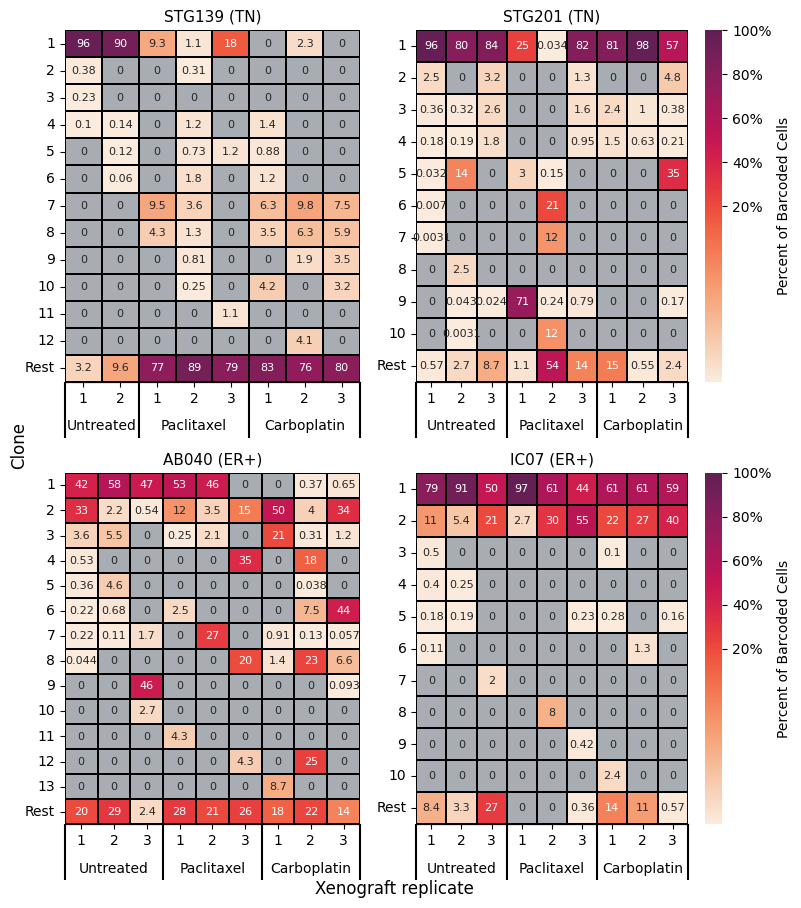

In [14]:
# Graph heatmaps of top X most prevalent clones in each tumor by the percent they make up of the tumor
## NOTE: If any of the top X are in another column, there will be fewer rows in the final heatmap
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap

plt.rcdefaults()

num_top_clones = 3
dict_of_dfs_heatmap = {}
mice = [1, 2, 3]
fmt = lambda x,pos: '{:.0%}'.format(x/100)
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

for key, val in clonal_comp_for_bargraph_treated_response.items():
    df = pd.DataFrame(val)
    if key == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    
    # Adjust dataframe
    top_barcodes = []
    for cohort in df["Cohort"].unique():
        for mouse in range(1, 4):
            curr_df = df.copy()
            curr_df = curr_df.loc[(curr_df["Cohort"] == cohort) & (curr_df["Mouse"] == mouse)].sort_values("Cell counts", ascending=False).reset_index(drop=True)
            top_clones = curr_df.head(num_top_clones)
            barcodes = top_clones["Barcode"].to_list()
            top_barcodes.extend(barcodes)
    
    top_barcodes = list(set(top_barcodes))
    top_clones_df = df.loc[df["Barcode"].isin(top_barcodes)]
    top_clones_df = top_clones_df.sort_values(["Cohort", "Mouse", "Cell counts"], ascending=[False, True, False]).reset_index(drop=True)
    
    remaining_df = df.loc[~df["Barcode"].isin(top_barcodes)]
    remaining_df = remaining_df.groupby(["Cohort", "Mouse"]).sum().reset_index()
    remaining_df["Response"] = "Resistant"
    remaining_df["Barcode"] = "All remaining"

    final_df = pd.concat([top_clones_df, remaining_df]).sort_values(["Cohort", "Mouse", "Percent"], ascending = [False, True, False]).reset_index(drop=True)
    final_df["Cohort mouse"] = final_df["Cohort"] + " " + final_df["Mouse"].astype("str")

    dict_of_dfs_heatmap[key] = final_df

key_order = ["STG139", "STG201", "AB040", "IC07"]
sorted_dict = {}
for key in key_order:
    if key in dict_of_dfs_heatmap:  
        sorted_dict[key] = dict_of_dfs_heatmap[key]

# Set up figure with subplots
fig, ax = plt.subplots(2, 2, figsize=(8, 9), width_ratios=[1, 1.15])
# Keep track of subplots
counter = 0
# Iterate through models
for axis, (key, val) in zip(ax.flatten(), sorted_dict.items()):
    # Grab the data & organize
    plot_df = val[["Cohort mouse", "Barcode", "Percent"]]
    pivot_df = plot_df.pivot(index='Barcode', columns='Cohort mouse', values='Percent').fillna(0)
    if key != "STG139":
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Untreated 3', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)
    else:
        pivot_df = pivot_df[['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3']].sort_values(['Untreated 1', 'Untreated 2', 'Paclitaxel 1', 'Paclitaxel 2', 'Paclitaxel 3', 'Carboplatin 1', 'Carboplatin 2', 'Carboplatin 3'], ascending=False)
    all_remaining = pivot_df.loc["All remaining"]
    pivot_df = pivot_df.drop(["All remaining"], axis=0).reset_index(drop=True)
    pivot_df.index = pivot_df.index + 1
    pivot_df.loc["Rest"] = all_remaining

    # Get the reversed rocket colormap
    rocket_r = mpl.colormaps["rocket_r"]
    # Skip the darkest part (e.g., first 20%) to avoid black
    rocket_r_adjust = ListedColormap(rocket_r(np.linspace(0, 0.75, 256)))
    # Set the color for masked values to a light gray
    rocket_r_adjust.set_under(color="#a7adb2")

    vmin, vmax = 0.000000001, 100
    vcenter = 20
    normalize = mcolors.TwoSlopeNorm(vcenter=vcenter, vmin=vmin, vmax=vmax)
    
    # Construct heatmaps for total and shared clones
    if axis in [ax[0,1], ax[1,1]]:
        sns.heatmap(data=pivot_df, 
                    cmap=rocket_r_adjust, 
                    norm=normalize, 
                    vmin=vmin, 
                    vmax=vmax, 
                    ax=axis,
                    linewidths=0.2, 
                    linecolor='black',
                    annot=True, 
                    fmt="0.2g",
                    annot_kws={"size": 8},
                    cbar_kws={
                        "format": FuncFormatter(fmt),
                        "label": "Percent of Barcoded Cells"
                    })
    else:
        sns.heatmap(data=pivot_df, 
                    cmap=rocket_r_adjust, 
                    norm=normalize, 
                    vmin=vmin, 
                    vmax=vmax, 
                    ax=axis,
                    linewidths=0.2, 
                    linecolor='black',
                    cbar=False,
                    annot=True, 
                    fmt="0.2g",
                    annot_kws={"size": 8},
                    cbar_kws={
                        "format": FuncFormatter(fmt),
                        "label": "Percent of Barcoded Cells"
                    })
        
    # Set up plot parameters
    axis.set_title(f"{key} ({model_type[key]})", fontsize=11)
    axis.set_yticklabels(axis.get_yticklabels(), rotation=0, fontsize=10)
    axis.set(xlabel=None, ylabel=None)

    if key == "STG139":
        axis.set_xticklabels(labels=["1", "2", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = axis.secondary_xaxis(location=0)
        sec.set_xticks([1, 3.5, 6.5], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = axis.secondary_xaxis(location=0)
        sec2.set_xticks([0, 2, 5, 8], labels=[])
        sec2.tick_params('x', length=40, width=1.5)

    else:
        axis.set_xticklabels(labels=["1", "2", "3", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = axis.secondary_xaxis(location=0)
        sec.set_xticks([1.5, 4.5, 7.5], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = axis.secondary_xaxis(location=0)
        sec2.set_xticks([0, 3, 6, 9], labels=[])
        sec2.tick_params('x', length=40, width=1.5)

    counter += 1
fig.text(0.48, 0.001, "Xenograft replicate", ha="center", fontsize=12)
fig.text(0, 0.5, "Clone", rotation="vertical", va="center", fontsize=12)
fig.tight_layout()
plt.rcParams['font.family'] = 'Arial'
plt.savefig("../visualizations/amplicon/amplicon_heatmap_clonal_composition.svg")
plt.show()

In [15]:
# Set up table to summarize unique clones in each cohort - binary, broken down more: number of each clone type that's sensitive/ resistant
## Set up index and columns for dataframe
models = full_data["Tumor"].unique()
secondary_cohorts = ["Untreated", "Carboplatin", "Paclitaxel"]
unique_bc_seqs = full_data.drop_duplicates(subset=["Tumor", "Cohort", "Mouse", "var_seq"])

summary_data = {}

# Summarize transient, propagating, and emerging clones and their response to treatment
for tumor in models:
    if tumor != "STG139":
        summary_info = {"common": {
                            "primary clones": 0,
                            "transient": 0
                        },
                        "secondaries": { 
                            "Untreated": {
                                "Unique clones": 0,
                                "Replicate 1": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 2": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 3": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                            },
                            "Carboplatin": {
                                "Unique clones": 0,
                                "Replicate 1": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 2": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 3": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                            },
                            "Paclitaxel": {
                                "Unique clones": 0,
                                "Replicate 1": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 2": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                },
                                "Replicate 3": {
                                    "total": 0, 
                                    "propagating Diminished": 0, 
                                    "propagating Expanded": 0, 
                                    "propagating Minimal change": 0,
                                    "emerging Diminished": 0, 
                                    "emerging Expanded": 0, 
                                    "emerging Minimal change": 0
                                }
                        }}}
    else:
        summary_info = {"common": {
                        "primary clones": 0,
                        "transient": 0
                    },
                    "secondaries": { 
                        "Untreated": {
                            "Unique clones": 0,
                            "Replicate 1": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 2": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            }
                        },
                        "Paclitaxel": {
                            "Unique clones": 0,
                            "Replicate 1": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 2": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 3": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                        },
                        "Carboplatin": {
                            "Unique clones": 0,
                            "Replicate 1": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 2": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            },
                            "Replicate 3": {
                                "total": 0, 
                                "propagating Diminished": 0, 
                                "propagating Expanded": 0, 
                                "propagating Minimal change": 0,
                                "emerging Diminished": 0, 
                                "emerging Expanded": 0, 
                                "emerging Minimal change": 0
                            }
                    }}}
    for bc_dict in full_stats[tumor]:
        cohort_info = bc_dict["secondary cohort info"]
        bc_info = bc_dict["barcode info"]
        if bc_info["secondary_presence"] > 0:
            if bc_info["primary_cells"] > 0:
                prop_emerg = "propagating"
                summary_info["common"]["primary clones"] += 1
            else:
                prop_emerg = "emerging"
            for cohort in cohort_info.keys():
                if cohort_info[cohort]["presence"] > 0:
                    summary_info["secondaries"][cohort]["Unique clones"] += 1
                    for i, response in enumerate(cohort_info[cohort]["all_treated_responses"]):
                        if response != "Not present":
                            if cohort != "Untreated":
                                summary_info["secondaries"][cohort][f"Replicate {i+1}"][f"{prop_emerg} {response}"] += 1
                                summary_info["secondaries"][cohort][f"Replicate {i+1}"]["total"] += 1
                            else:
                                summary_info["secondaries"][cohort][f"Replicate {i+1}"][f"{prop_emerg} Diminished"] += 1
                                summary_info["secondaries"][cohort][f"Replicate {i+1}"]["total"] += 1
        elif bc_info["secondary_presence"] == 0 and bc_info["primary_cells"] > 0:
            summary_info["common"]["primary clones"] += 1
            summary_info["common"]["transient"] += 1    

    for cohort in summary_info["secondaries"].keys():
        if tumor == "STG139" and cohort == "Untreated":
            summary_data[(tumor, cohort, "Replicate 1")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 1"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 1"]["propagating Diminished"], 
            summary_info["secondaries"][cohort]["Replicate 1"]["propagating Minimal change"],summary_info["secondaries"][cohort]["Replicate 1"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Expanded"]]

            summary_data[(tumor, cohort, "Replicate 2")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 2"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Diminished"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Minimal change"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Expanded"]]

        else:
            summary_data[(tumor, cohort, "Replicate 1")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 1"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 1"]["propagating Diminished"], summary_info["secondaries"][cohort]["Replicate 1"]["propagating Minimal change"], summary_info["secondaries"][cohort]["Replicate 1"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 1"]["emerging Expanded"]]

            summary_data[(tumor, cohort, "Replicate 2")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 2"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Diminished"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Minimal change"], summary_info["secondaries"][cohort]["Replicate 2"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 2"]["emerging Expanded"]]

            summary_data[(tumor, cohort, "Replicate 3")] = [summary_info["common"]["primary clones"], summary_info["secondaries"][cohort]["Unique clones"], summary_info["secondaries"][cohort]["Replicate 3"]["total"], summary_info["common"]["transient"], summary_info["secondaries"][cohort]["Replicate 3"]["propagating Diminished"], summary_info["secondaries"][cohort]["Replicate 3"]["propagating Minimal change"], summary_info["secondaries"][cohort]["Replicate 3"]["propagating Expanded"], summary_info["secondaries"][cohort]["Replicate 3"]["emerging Diminished"], summary_info["secondaries"][cohort]["Replicate 3"]["emerging Minimal change"], summary_info["secondaries"][cohort]["Replicate 3"]["emerging Expanded"]]

# Convert to dataframe
index = pd.MultiIndex.from_tuples([("", "", "Unique clones primary PDTX"), 
                                   ("", "", "Unique clones secondary PDTX"), 
                                   ("", "", "Unique clones per replicate"),
                                   ("Clone type & treatment response", "Transient", ""), 
                                   ("Clone type & treatment response", "Propagating", "Diminished"), ("Clone type & treatment response", "Propagating", "Minimal change"), 
                                   ("Clone type & treatment response", "Propagating", "Expanded"), 
                                   ("Clone type & treatment response", "Emerging", "Diminished"), ("Clone type & treatment response", "Emerging", "Minimal change"), 
                                   ("Clone type & treatment response", "Emerging", "Expanded")])
summary_df_v6 = pd.DataFrame(summary_data, index=index).transpose()

# Output to csv
summary_df_v6.to_excel("../data_files/amplicon_data/amplicon_num_clones_by_chemoResponse_propTransEmerg_replicate.xlsx")

# Print dataframe
summary_df_v6

\
                                                            
                               Unique clones primary PDTX   
AB040  Untreated   Replicate 1                        322   
                   Replicate 2                        322   
                   Replicate 3                        322   
       Carboplatin Replicate 1                        322   
                   Replicate 2                        322   
                   Replicate 3                        322   
       Paclitaxel  Replicate 1                        322   
                   Replicate 2                        322   
                   Replicate 3                        322   
IC07   Untreated   Replicate 1                        197   
                   Replicate 2                        197   
                   Replicate 3                        197   
       Carboplatin Replicate 1                        197   
                   Replicate 2                        197   
                   Replicate 3                        197   
       Paclitaxel  Replicate 1                        197   
                   Replicate 2                        197   
                   Replicate 3                        197   
STG139 Untreated   Replicate 1                          6   
                   Replicate 2                          6   
       Paclitaxel  Replicate 1                          6   
                   Replicate 2                          6   
                   Replicate 3                          6   
       Carboplatin Replicate 1                          6   
                   Replicate 2                          6   
                   Replicate 3                          6   
STG201 Untreated   Replicate 1                         54   
                   Replicate 2                         54   
                   Replicate 3                         54   
       Carboplatin Replicate 1                         54   
                   Replicate 2                         54   
                   Replicate 3                         54   
       Paclitaxel  Replicate 1                         54   
                   Replicate 2                         54   
                   Replicate 3                         54   

                                                             \
                                                              
                               Unique clones secondary PDTX   
AB040  Untreated   Replicate 1                          294   
                   Replicate 2                          294   
                   Replicate 3                          294   
       Carboplatin Replicate 1                          396   
                   Replicate 2                          396   
                   Replicate 3                          396   
       Paclitaxel  Replicate 1                          210   
                   Replicate 2                          210   
                   Replicate 3                          210   
IC07   Untreated   Replicate 1                          121   
                   Replicate 2                          121   
                   Replicate 3                          121   
       Carboplatin Replicate 1                          153   
                   Replicate 2                          153   
                   Replicate 3                          153   
       Paclitaxel  Replicate 1                           10   
                   Replicate 2                           10   
                   Replicate 3                           10   
STG139 Untreated   Replicate 1                          161   
                   Replicate 2                          161   
       Paclitaxel  Replicate 1                          343   
                   Replicate 2                          343   
                   Replicate 3                          343   
       Carboplatin Replicate 1                          165   
                   Replicate 2         

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/4083520437.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels=ax.get_yticklabels(), fontsize=10)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/4083520437.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=["1", "2", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/4083520437.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels=ax.get_yticklabels(), fontsize=10)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/4083520437.py:70: UserWarning: set_ticklabels() should only be used with a fixed numb

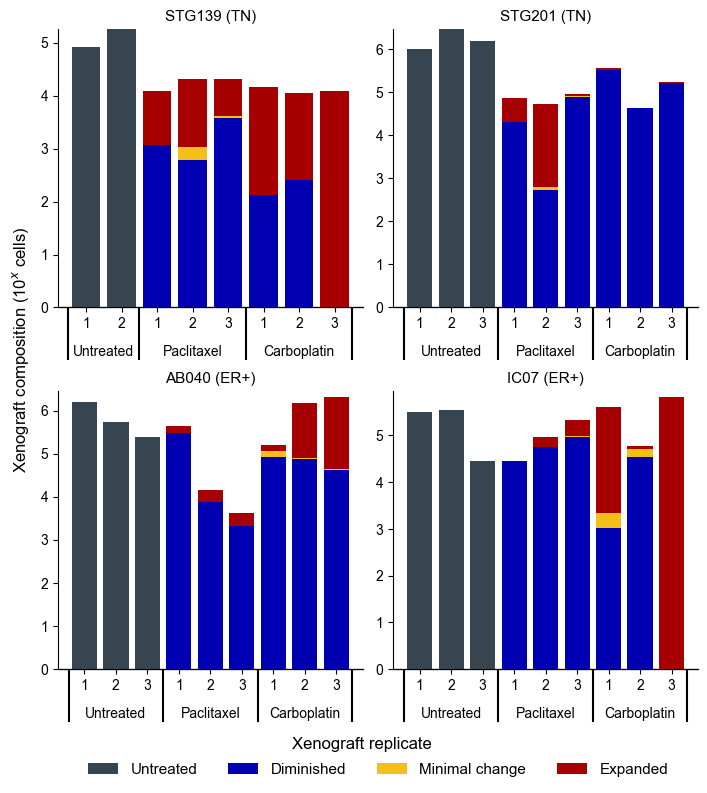

In [16]:
# Plot all chemo response percentage bar charts together 2 rows 2 columns and save
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.flatten()

counter = 1

colors = ["#36454F", "#0000b3", "#F5BE19", "#a70000"]
responses = ["Untreated", "Diminished", "Minimal change",  "Expanded"]
color_map = dict(zip(responses, colors))
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

dict_of_dfs = {}

for model in ["STG139", "STG201", "AB040", "IC07"]: 
    df = pd.DataFrame(response_classes_for_bargraph_treated_response[model])
    if key == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    df = df.sort_values("Cohort", ascending=False)
    df['Response'] = df['Response'].str.removesuffix(" (1 Replicate)")
    df = df.groupby(["Cohort", "Mouse", "Response"]).sum().reset_index()
    dict_of_dfs[model] = df

for model, (i, ax) in zip(dict_of_dfs.keys(), enumerate(axes)):
    plot_df = dict_of_dfs[model]
    plot_df['x_category'] = plot_df["Cohort"] + " " + plot_df["Mouse"].astype(str)

    if model == "STG139":
        x_order_tuples = [("Untreated", 1), ("Untreated", 2), ("Paclitaxel", 1), ("Paclitaxel", 2), ("Paclitaxel", 3),
                ("Carboplatin", 1), ("Carboplatin", 2), ("Carboplatin", 3)]
    else:
        x_order_tuples = [("Untreated", 1), ("Untreated", 2), ("Untreated", 3), ("Paclitaxel", 1), ("Paclitaxel", 2), 
                        ("Paclitaxel", 3), ("Carboplatin", 1), ("Carboplatin", 2), ("Carboplatin", 3)]
    x_tick_labels = [f"{cohort} {mouse}" for cohort, mouse in x_order_tuples]

    pivot_cells = plot_df.pivot(index='x_category', columns='Response', values='Cell counts').reindex(x_tick_labels, columns=responses).fillna(0)

    bottom = np.zeros(len(pivot_cells))
    for response_type in pivot_cells.columns:
        percentages = pivot_cells[response_type].values
        ax.bar(pivot_cells.index,
               percentages, 
               bottom = bottom, 
               label = response_type, 
               color = color_map[response_type],
               width=0.8
            )
        bottom += percentages

    ax.grid(False)
    ax.set_yscale("log")
    ax.set_ylim(bottom=1, top=None)
    ax.set_title(f"{model} ({model_type[model]})", fontsize=11)
    ax.set_yticklabels(labels=ax.get_yticklabels(), fontsize=10)
    ax.yaxis.minorticks_off()
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(log_tick_formatter))

    if model == "STG139":
        ax.set_xticklabels(labels=["1", "2", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = ax.secondary_xaxis(location=0)
        sec.set_xticks([0.5, 3, 6], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = ax.secondary_xaxis(location=0)
        sec2.set_xticks([-0.5, 1.5, 4.5, 7.5], labels=[])
        sec2.tick_params('x', length=38, width=1.5)
    else:
        ax.set_xticklabels(labels=["1", "2", "3", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = ax.secondary_xaxis(location=0)
        sec.set_xticks([1, 4, 7], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = ax.secondary_xaxis(location=0)
        sec2.set_xticks([-0.5, 2.5, 5.5, 8.5], labels=[])
        sec2.tick_params('x', length=38, width=1.5)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.0001), ncol=len(responses), frameon=False, fontsize=11)
fig.text(0.48, 0.001, "Xenograft replicate", ha="center", fontsize=12)
fig.text(0.04, 0.5, "Xenograft composition (10$^{x}$ cells)", rotation="vertical", va="center", fontsize=12)
fig.tight_layout()
sns.despine()
plt.subplots_adjust(wspace=0.1, hspace=0.3, left=0.1, right=0.9, top=0.9, bottom=0.1)
plt.rcParams.update({'font.family': 'Arial', 'font.size': 12})

plt.savefig("../visualizations/amplicon/amplicon_PDX_compositionByResponse_bargraph_num_cells.svg", format="svg", bbox_inches='tight')
plt.show()

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1253383521.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels=ax.get_yticklabels(), fontsize=10)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1253383521.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=["1", "2", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1253383521.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels=ax.get_yticklabels(), fontsize=10)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/1253383521.py:68: UserWarning: set_ticklabels() should only be used with a fixed numb

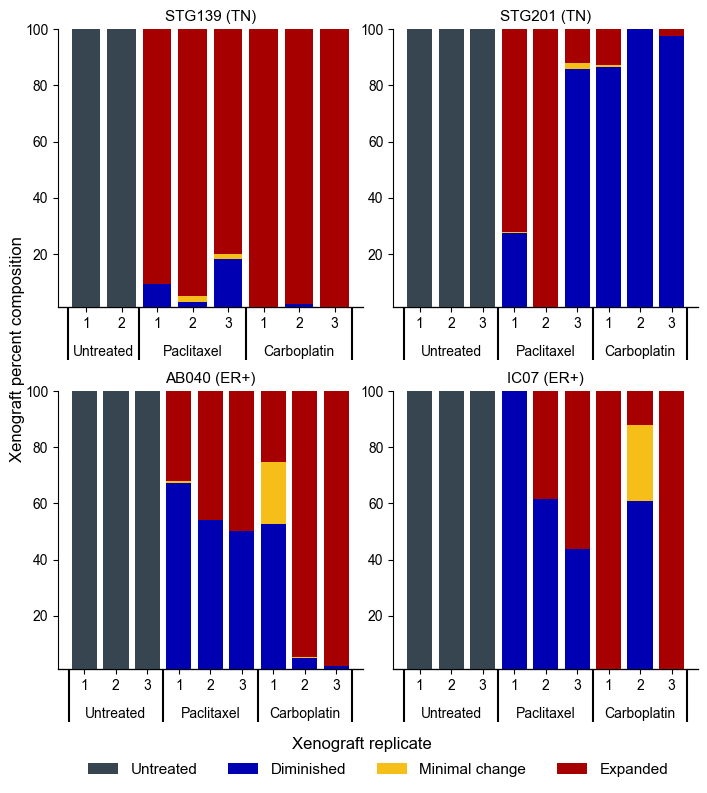

In [17]:
# Plot all chemo response percentage bar charts together 2 rows 2 columns and save
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.flatten()

counter = 1

colors = ["#36454F", "#0000b3", "#F5BE19", "#a70000"]
responses = ["Untreated", "Diminished", "Minimal change",  "Expanded"]
color_map = dict(zip(responses, colors))
model_type = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}

dict_of_dfs = {}

for model in ["STG139", "STG201", "AB040", "IC07"]: 
    df = pd.DataFrame(response_classes_for_bargraph_treated_response[model])
    if key == "STG139":
        df = df.drop(df[(df["Cohort"] == "Untreated") & (df["Mouse"] == 3)].index)
    df = df.sort_values("Cohort", ascending=False)
    df['Response'] = df['Response'].str.removesuffix(" (1 Replicate)")
    df = df.groupby(["Cohort", "Mouse", "Response"]).sum().reset_index()
    dict_of_dfs[model] = df

for model, (i, ax) in zip(dict_of_dfs.keys(), enumerate(axes)):
    plot_df = dict_of_dfs[model]
    plot_df['x_category'] = plot_df["Cohort"] + " " + plot_df["Mouse"].astype(str)

    if model == "STG139":
        x_order_tuples = [("Untreated", 1), ("Untreated", 2), ("Paclitaxel", 1), ("Paclitaxel", 2), ("Paclitaxel", 3),
                ("Carboplatin", 1), ("Carboplatin", 2), ("Carboplatin", 3)]
    else:
        x_order_tuples = [("Untreated", 1), ("Untreated", 2), ("Untreated", 3), ("Paclitaxel", 1), ("Paclitaxel", 2), 
                        ("Paclitaxel", 3), ("Carboplatin", 1), ("Carboplatin", 2), ("Carboplatin", 3)]
    x_tick_labels = [f"{cohort} {mouse}" for cohort, mouse in x_order_tuples]

    pivot_cells = plot_df.pivot(index='x_category', columns='Response', values='Percent').reindex(x_tick_labels, columns=responses).fillna(0)

    bottom = np.zeros(len(pivot_cells))
    for response_type in pivot_cells.columns:
        percentages = pivot_cells[response_type].values
        ax.bar(pivot_cells.index,
               percentages, 
               bottom = bottom, 
               label = response_type, 
               color = color_map[response_type],
               width=0.8
            )
        bottom += percentages

    ax.grid(False)
    ax.set_ylim(bottom=1, top=100)
    ax.set_title(f"{model} ({model_type[model]})", fontsize=11)
    ax.set_yticklabels(labels=ax.get_yticklabels(), fontsize=10)
    ax.yaxis.minorticks_off()

    if model == "STG139":
        ax.set_xticklabels(labels=["1", "2", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = ax.secondary_xaxis(location=0)
        sec.set_xticks([0.5, 3, 6], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = ax.secondary_xaxis(location=0)
        sec2.set_xticks([-0.5, 1.5, 4.5, 7.5], labels=[])
        sec2.tick_params('x', length=38, width=1.5)
    else:
        ax.set_xticklabels(labels=["1", "2", "3", "1", "2", "3", "1", "2", "3"], rotation=0, fontsize=10)

        # label the classes:
        sec = ax.secondary_xaxis(location=0)
        sec.set_xticks([1, 4, 7], labels=['\n\nUntreated', '\n\nPaclitaxel', '\n\nCarboplatin'], fontsize=10)
        sec.tick_params('x', length=0)

        # lines between the classes:
        sec2 = ax.secondary_xaxis(location=0)
        sec2.set_xticks([-0.5, 2.5, 5.5, 8.5], labels=[])
        sec2.tick_params('x', length=38, width=1.5)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.0001), ncol=len(responses), frameon=False, fontsize=11)
fig.text(0.48, 0.001, "Xenograft replicate", ha="center", fontsize=12)
fig.text(0.04, 0.5, "Xenograft percent composition", rotation="vertical", va="center", fontsize=12)
fig.tight_layout()
sns.despine()
plt.subplots_adjust(wspace=0.1, hspace=0.3, left=0.1, right=0.9, top=0.9, bottom=0.1)
plt.rcParams.update({'font.family': 'Arial', 'font.size': 12})

plt.savefig("../visualizations/amplicon/amplicon_PDX_compositionByResponse_bargraph_percent.svg", format="svg", bbox_inches='tight')
plt.show()

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/4145697973.py:51: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1.5}` instead.

  sns.barplot(ax=ax, x="Response", y="Change from Untreated",
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/4145697973.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/4145697973.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels=ax.get_yticklabels(), fontsize=9)
/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_8317/4145697973.py:51: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={

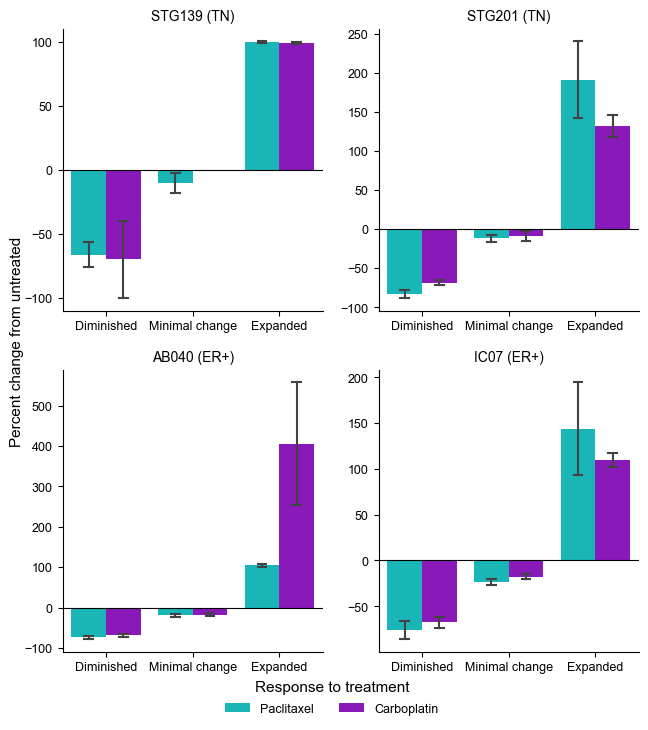

In [18]:
# Bar graph to show average clone size change per model per response

def get_df(row_meta_list):
    data = []
    for item in row_meta_list:
        barcode_info = item["barcode info"]
        secondary_info = item["secondary cohort info"]
        barcode = barcode_info["barcode"]

        for cohort in ["Paclitaxel", "Carboplatin"]:
            for i in range(0, 3):
                bc_data = {}
                bc_data["mouse"] = i+1
                bc_data["barcode"] = barcode
                bc_data["Cohort"] = cohort
                bc_data["Change from Untreated"] = barcode_info[f"Percent change: Untreated to {cohort}"][i]
                secondary_presence = barcode_info["secondary_presence"]
                if secondary_presence == 0:
                    bc_data["Response"] = "Not present in Secondaries"
                else:
                    bc_data["Response"] = secondary_info[cohort]["all_treated_responses"][i]
                    
                data.append(bc_data)
        
    data_df = pd.DataFrame(data)
    data_df = data_df[data_df['Response'] != "Not present in Secondaries"].reset_index(drop=True)

    return data_df    

def log_tick_formatter_v2(val, pos):
    if val == 0:
        return 0
    exponent = int(round(np.log10(abs(val))))
    if val < 0:
        return f'-{exponent}'
    return f'{exponent}'

model_type = {"STG139": "TN", "STG201": "TN", "AB040": "ER+", "IC07": "ER+"}

color_map = {
    "Paclitaxel": "darkturquoise",
    "Carboplatin": "darkviolet"
}
ax_order = ["Diminished", "Minimal change", "Expanded"]

fig, axes = plt.subplots(2, 2, figsize=(6.5, 7))
sns.reset_defaults()
for i, ax in enumerate(fig.axes):
    model = list(model_type.keys())[i]
    data = get_df(full_stats[model])[["Cohort", "Response", "Change from Untreated"]]
    sns.barplot(ax=ax, x="Response", y="Change from Untreated",
            hue="Cohort",
            palette=color_map, 
            data=data, 
            capsize=0.2,
            errwidth=1.5,
            errorbar="se", 
            order=ax_order)
    ax.set_title(f"{model} ({model_type[model]})", fontsize=10)
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=9)
    ax.set_yticklabels(labels=ax.get_yticklabels(), fontsize=9)
    ax.yaxis.minorticks_off()
    ax.set(xlabel=None, ylabel=None)
    ax.axhline(0, color='black', linestyle='-', linewidth=0.8)
    ax.get_legend().remove()

handles, labels = axes[0,0].get_legend_handles_labels()    
plt.rcParams.update({'font.family': 'Arial', 'font.size': 12})
fig.text(0.5, 0, "Response to treatment", ha="center", fontsize=11)
fig.text(0.005, 0.5, "Percent change from untreated", rotation="vertical", va="center", fontsize=11)
sns.despine()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.05), fontsize=9, ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(f"../visualizations/amplicon/amplicon_treated_response_classification_bargraph.svg", bbox_inches='tight')
plt.show()


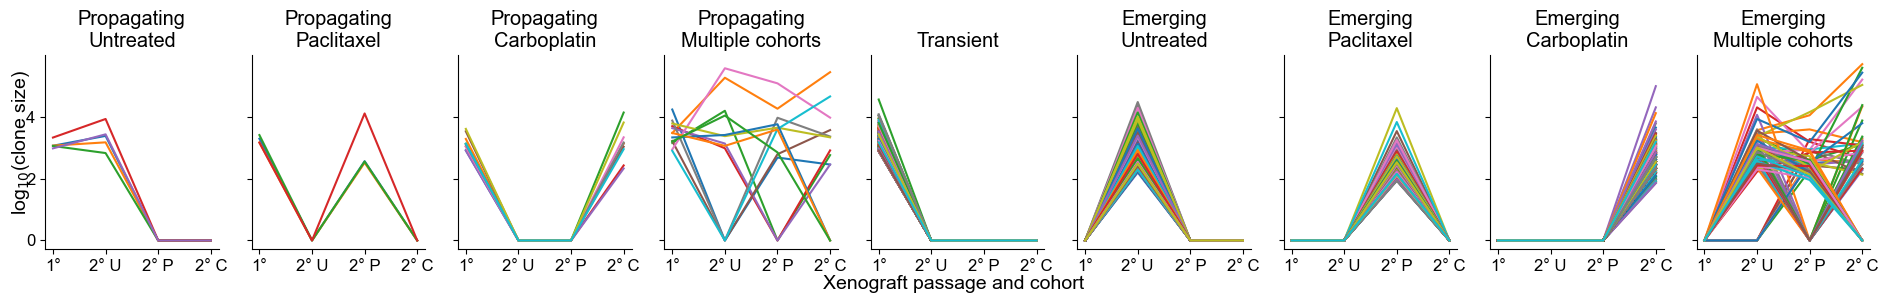

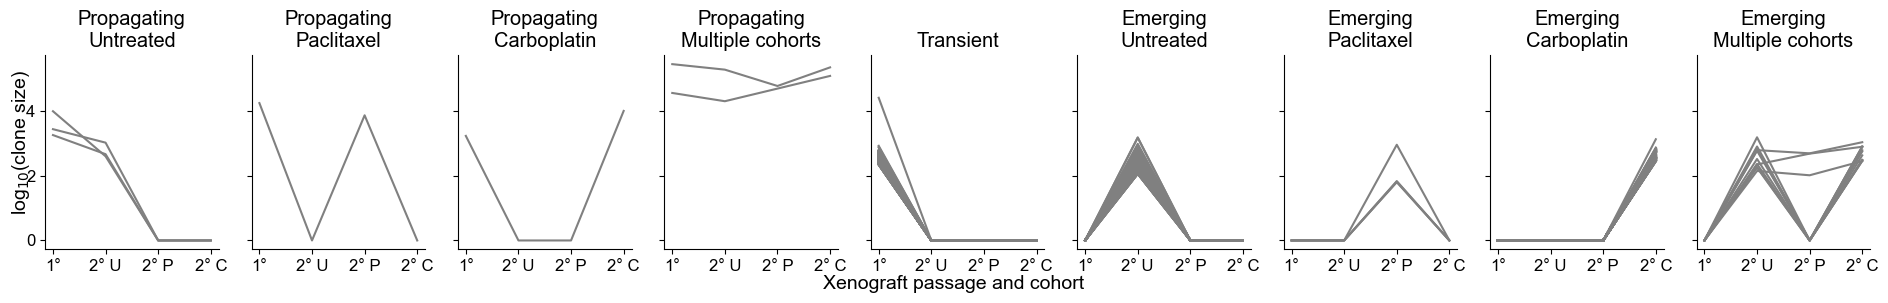

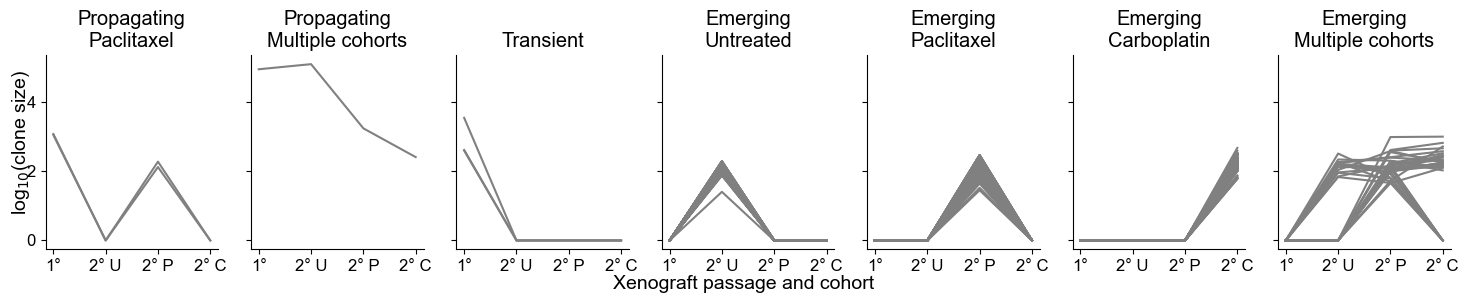

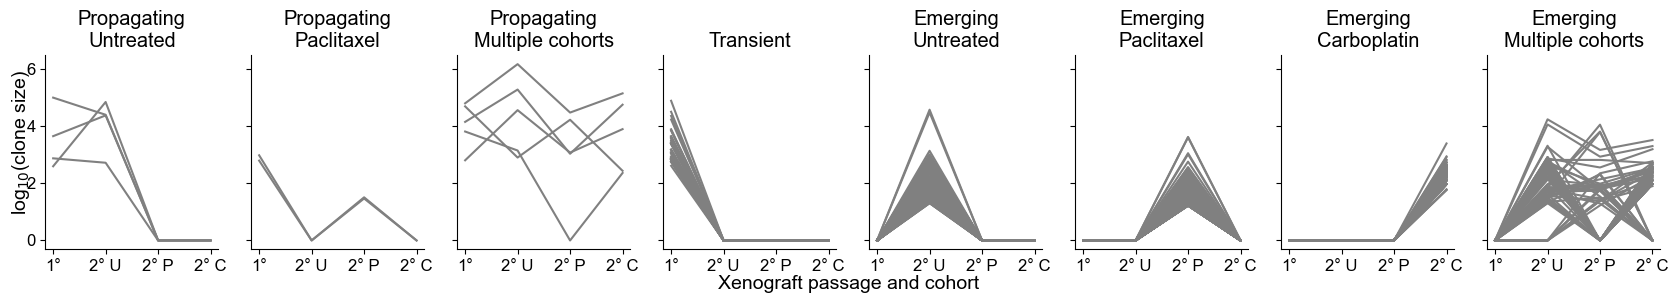

In [19]:
# Create line graphs for number of cells with each barcode in primary and each secondary cohort for propagating, emerging, and transient clones
## Cell numbers are the average of all nonzero cell counts within each cohort
models = ["AB040", "IC07", "STG139", "STG201"]
for model in models:
    model_info = seq_info[model]
    model_info = model_info.replace(0, np.nan).dropna(how="all")
    model_info["Untreated"] = model_info[["Untreated 1", "Untreated 2", "Untreated 3"]].mean(axis=1)
    model_info["Paclitaxel"] = model_info[["Paclitaxel 1", "Paclitaxel 2", "Paclitaxel 3"]].mean(axis=1)
    model_info["Carboplatin"] = model_info[["Carboplatin 1", "Carboplatin 2", "Carboplatin 3"]].mean(axis=1)
    model_info = model_info[["Primary", "Untreated", "Paclitaxel", "Carboplatin"]]

    primary_clones = model_info["Primary"].notna()
    secondary_clones = model_info[["Untreated", "Paclitaxel", "Carboplatin"]].notna().any(axis=1)
    secondary_clones_multi_cohort = model_info[["Untreated", "Paclitaxel", "Carboplatin"]].notna().sum(axis=1) >= 2
    secondary_clones_untreated = model_info["Untreated"].notna()
    secondary_clones_pac = model_info["Paclitaxel"].notna()
    secondary_clones_carb = model_info["Carboplatin"].notna()

    propagating_untreated = model_info[primary_clones & secondary_clones_untreated & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    propagating_pac = model_info[primary_clones & secondary_clones_pac & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    propagating_carb = model_info[primary_clones & secondary_clones_carb & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    propagating_multi = model_info[primary_clones & secondary_clones_multi_cohort].fillna(1).apply(np.log10)

    transient = model_info[primary_clones & ~secondary_clones].fillna(1).apply(np.log10)

    emerging_untreated = model_info[~primary_clones & secondary_clones_untreated & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    emerging_pac = model_info[~primary_clones & secondary_clones_pac & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    emerging_carb = model_info[~primary_clones & secondary_clones_carb & ~secondary_clones_multi_cohort].fillna(1).apply(np.log10)
    emerging_multi = model_info[~primary_clones & secondary_clones_multi_cohort].fillna(1).apply(np.log10)

    plot_data = [
        (propagating_untreated, "Propagating\nUntreated"),
        (propagating_pac, "Propagating\nPaclitaxel"), 
        (propagating_carb, "Propagating\nCarboplatin"), 
        (propagating_multi, "Propagating\nMultiple cohorts"),
        (transient, "Transient"),
        (emerging_untreated, "Emerging\nUntreated"),
        (emerging_pac, "Emerging\nPaclitaxel"),
        (emerging_carb, "Emerging\nCarboplatin"),
        (emerging_multi, "Emerging\nMultiple cohorts")
    ]

    valid_plots = [(df, title) for df, title in plot_data if not df.empty]

    n_plots = len(valid_plots)

    fig, axes = plt.subplots(1, n_plots, figsize=(2.1*n_plots, 3), sharey=True)

    if n_plots == 1:
        axes = [axes]

    for i, (df, title) in enumerate(valid_plots):
        ax = axes[i]
        df.T.plot(kind="line", legend=False, title=title, ax=ax)
        ax.minorticks_off()
        ax.set_xticks([0, 1, 2, 3])
        ax.set_xticklabels(["1\xb0", "2\xb0 U", "2\xb0 P", "2\xb0 C"])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    # plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.tight_layout()
    plt.rc('axes', prop_cycle=(cycler('color', ['grey'])))
    # plt.suptitle(f"{model}")
    fig.text(0.5, 0.01, "Xenograft passage and cohort", ha="center", fontsize=14)
    fig.text(0.001, 0.5, "log$_{10}$(clone size) ", rotation="vertical", va="center", fontsize=14)
    plt.savefig(f"../visualizations/amplicon/amplicon_{model}_prop_trans_emerg_clone_size_line_graphs.svg")
    plt.show()



In [38]:
seq_info_AB040 = seq_info_AB040[seq_info_AB040.ne(0.0).any(axis=1)]
non_zero_counts = (seq_info_AB040 != 0).sum()
non_zero_counts
seq_info_AB040_secondary = seq_info_AB040.drop("Primary", axis=1)
seq_info_AB040_secondary[seq_info_AB040_secondary.ne(0.0).any(axis=1)]


,Untreated 1,Untreated 2,Untreated 3,Carboplatin 1,Carboplatin 2,Carboplatin 3,Paclitaxel 1,Paclitaxel 2,Paclitaxel 3
Sequence,,,,,,,,,
ACTGAAATCAAGATCCAAATAGGTCGAACCT,0.0,0.00,0.00,394.79,0.0,0.0,315.33,0.0,0.0
ACTGAAATCAAGATGGAAAAAGGTAAAACAC,0.0,0.00,0.00,179.69,0.0,0.0,0.00,0.0,0.0
ACTGAAATCAGGATGCAAACTGGTTAAACAG,0.0,0.00,0.00,312.68,0.0,0.0,425.99,0.0,0.0
ACTGAAATCCGGATCGAAATAGGTACAACTA,0.0,0.00,0.00,207.47,0.0,0.0,0.00,0.0,0.0
ACTGAAATCCGGATGCAAAGTGGTTAAACGG,0.0,3687.07,368.35,1280.47,0.0,0.0,390.52,0.0,0.0
...,...,...,...,...,...,...,...,...,...
ACTGTGATCAGGATCGAAAGGGGTGGAACCT,0.0,304.65,0.00,0.00,0.0,0.0,0.00,0.0,0.0
ACTGTGATCGCGATCCAAAAAGGTGTAACCC,0.0,264.06,0.00,0.00,0.0,0.0,0.00,0.0,0.0
ACTGTGATCGGGATGCAAAATGGTATAACCC,0.0,343.16,0.00,0.00,0.0,0.0,0.00,0.0,0.0


In [42]:
seq_info_IC07 = seq_info_IC07[seq_info_IC07.ne(0.0).any(axis=1)]
seq_info_IC07
non_zero_counts = (seq_info_IC07 != 0).sum()
non_zero_counts
seq_info_IC07_secondary = seq_info_IC07.drop("Primary", axis=1)
seq_info_IC07_secondary[seq_info_IC07_secondary.ne(0.0).any(axis=1)]

,Untreated 1,Untreated 2,Untreated 3,Carboplatin 1,Carboplatin 2,Carboplatin 3,Paclitaxel 1,Paclitaxel 2,Paclitaxel 3
Sequence,,,,,,,,,
ACTGAAATCAGGATGCAAACTGGTTAAACAG,465.30,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.00
ACTGACATCATGATGGAAAAGGGTACAACGC,0.00,0.00,0.0,536.17,0.00,0.0,0.00,0.00,0.00
ACTGATATCCCGATGCAAACTGGTAAAACTT,803.32,0.00,0.0,304.47,0.00,0.0,0.00,0.00,0.00
ACTGCAATCTGGATCCAAATAGGTGAAACGG,1245.60,869.08,0.0,0.00,0.00,0.0,0.00,0.00,0.00
ACTGCCATCCTGATCCAAACCGGTTAAACAA,245833.09,313283.43,14609.8,254679.87,35405.19,383946.3,28035.14,56648.69,94563.62
...,...,...,...,...,...,...,...,...,...
ACTGTAATCATGATCGAAACCGGTTGAACCC,0.00,361.63,0.0,0.00,0.00,0.0,0.00,0.00,0.00
ACTGTCATCCGGATGCAAAATGGTGAAACGA,0.00,270.46,0.0,0.00,0.00,0.0,0.00,0.00,0.00
ACTGTCATCCTGATCCAAAACGGTTAAACAA,0.00,152.63,0.0,0.00,0.00,0.0,0.00,0.00,0.00


In [45]:
seq_info_STG139 = seq_info_STG139[seq_info_STG139.ne(0.0).any(axis=1)]
seq_info_STG139
non_zero_counts = (seq_info_STG139 != 0).sum()
non_zero_counts
seq_info_STG139_secondary = seq_info_STG139.drop("Primary", axis=1)
seq_info_STG139_secondary[seq_info_STG139_secondary.ne(0.0).any(axis=1)]

,Untreated 1,Untreated 2,Untreated 3,Carboplatin 1,Carboplatin 2,Carboplatin 3,Paclitaxel 1,Paclitaxel 2,Paclitaxel 3
Sequence,,,,,,,,,
ACTGAAATCAGGATGCAAACTGGTTAAACAG,0.00,0.00,0,0.00,216.64,437.38,0.00,167.83,0.00
ACTGACATCATGATGGAAAAGGGTACAACGC,0.00,0.00,0,0.00,0.00,0.00,0.00,263.18,158.04
ACTGAGATCCGGATGGAAATCGGTTAAACAT,181.23,0.00,0,0.00,374.28,0.00,348.91,154.18,0.00
ACTGATATCCCGATGCAAACTGGTAAAACTT,0.00,0.00,0,0.00,0.00,0.00,0.00,75.94,0.00
ACTGCAATCCAGATGCAAAGCGGTGCAACAA,0.00,0.00,0,59.89,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...
ACTGTGATCGCGATCCAAAAAGGTCAAACCT,0.00,89.20,0,0.00,0.00,0.00,0.00,0.00,0.00
ACTGTTATCAAGATGGAAAAGGGTCAAACAC,0.00,141.97,0,0.00,0.00,0.00,0.00,0.00,0.00
ACTGTTATCAGGATGGAAAATGGTAGAACGG,0.00,96.28,0,0.00,0.00,0.00,0.00,0.00,0.00


In [48]:
seq_info_STG201 = seq_info_STG201[seq_info_STG201.ne(0.0).any(axis=1)]
seq_info_STG201
non_zero_counts = (seq_info_STG201 != 0).sum()
non_zero_counts
seq_info_STG201_secondary = seq_info_STG201.drop("Primary", axis=1)
seq_info_STG201_secondary[seq_info_STG201_secondary.ne(0.0).any(axis=1)]

,Untreated 1,Untreated 2,Untreated 3,Carboplatin 1,Carboplatin 2,Carboplatin 3,Paclitaxel 1,Paclitaxel 2,Paclitaxel 3
Sequence,,,,,,,,,
ACTGAAATCAAGATCCAAATAGGTCGAACCT,984386.77,2309827.47,1310007.32,296904.19,41731.97,95751.77,17500.46,18.25,74634.58
ACTGAAATCAGGATGCAAACTGGTTAAACAG,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,335.79
ACTGACATCATGATGGAAAAGGGTACAACGC,24.01,0.00,264.94,0.00,0.00,0.00,0.00,0.00,0.00
ACTGAGATCCGGATGGAAATCGGTTAAACAT,0.00,0.00,0.00,650.48,0.00,0.00,0.00,0.00,0.00
ACTGATATCCCGATGCAAACTGGTAAAACTT,0.00,0.00,0.00,210.37,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...
ACTGTTATCCCGATGCAAACCGGTATAACTA,0.00,41.51,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ACTGTTATCGTGATGCAAACGGGTCAAACTA,0.00,31.99,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ACTGTTATCGTGATGGAAAGCGGTAAAACAA,0.00,36.74,0.00,0.00,0.00,0.00,0.00,0.00,0.00
